# 「鲜果时光」连锁生鲜便利店 2025 年运营数据分析与可视化

**实验四 · 综合项目实践** 

## 0. 环境与全局配置

In [ ]:
import os, time, json, warnings, unicodedata
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from pyecharts import options as opts
from pyecharts.charts import Line, Pie, Sankey, Radar
from pyecharts.commons.utils import JsCode
import pyecharts; 

warnings.filterwarnings('ignore')
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 120
sns.set_theme(style='whitegrid', font=plt.rcParams['font.sans-serif'])

RAW, FIG = '原始数据', '图表'
os.makedirs(FIG, exist_ok=True)

pandas 2.3.3 | numpy 1.26.4 | matplotlib 3.10.7 | seaborn 0.13.2
pyecharts 2.1.0


## 1. 分表读取与概览

In [ ]:
sales_raw  = pd.read_csv(f'{RAW}/store_sales_2025.csv', encoding='utf-8-sig', dtype=str)
info_raw   = pd.read_csv(f'{RAW}/store_info.csv',      encoding='utf-8-sig', dtype=str)
member_raw = pd.read_csv(f'{RAW}/member_sales_2025.csv', encoding='utf-8-sig', dtype=str)
print('表形状(行,列):', sales_raw.shape, info_raw.shape, member_raw.shape)

overview = pd.DataFrame({
    '记录数': [len(sales_raw), len(info_raw), len(member_raw)],
    '字段数': [sales_raw.shape[1], info_raw.shape[1], member_raw.shape[1]],
    '完全重复行': [sales_raw.duplicated().sum(), info_raw.duplicated().sum(), member_raw.duplicated().sum()],
    '含缺失字段数': [(sales_raw.isna().sum() > 0).sum(), (info_raw.isna().sum() > 0).sum(), (member_raw.isna().sum() > 0).sum()],
}, index=['store_sales', 'store_info', 'member_sales'])
print(overview.to_string())
print('\n事实表缺失值明细:'); print(sales_raw.isna().sum()[sales_raw.isna().sum() > 0].to_string())
print('\n维度表缺失值明细:'); print(info_raw.isna().sum()[info_raw.isna().sum() > 0].to_string())
print('\n交易表缺失值明细:'); print(member_raw.isna().sum()[member_raw.isna().sum() > 0].to_string())
print('\n事实表前 3 行:'); print(sales_raw.head(3).to_string())

表形状(行,列): (9175, 18) (25, 10) (2500, 9)
               记录数  字段数  完全重复行  含缺失字段数
store_sales   9175   18     50       4
store_info      25   10      0       2
member_sales  2500    9      0       1

事实表缺失值明细:
气温(℃)     268
销售额(元)    228
客单价(元)    182
会员订单占比    182

维度表缺失值明细:
门店经度    5
门店纬度    5

交易表缺失值明细:
消费金额(元)    15

事实表前 3 行:
           日期 门店编码         门店名称  城市  区域 主推品类  天气 气温(℃) 是否促销 促销类型  销售额(元)  订单数 客单价(元) 会员订单占比   生鲜销售额   零食销售额   日百销售额  饮料销售额
0  2025/11/03  S12  鲜果时光(广州12店)  广州  新城   生鲜  多云  16.0    0    无  5567.0  199    NaN  0.347  2448.1  1144.3  1151.2  823.4
1  2025/07/18  S17  鲜果时光(广州17店)  广州  城区   日百  多云  41.4    1   折扣  6207.9  221   28.1  0.453  2653.4  1244.0  1371.4  939.1
2  2025-12-06  S14  鲜果时光(佛山14店)  佛山  城区   零食  多云  13.1    0    无  4444.0  112   39.7  0.258  1817.6   944.3   949.1  733.0


### 1.1 跨表一致性校验

In [ ]:
def to_half(x):
    # 全角 → 半角（NFKC 统一处理全角字母、数字与标点）
    return x if pd.isna(x) else unicodedata.normalize('NFKC', str(x))

def norm_code(x):
    return to_half(x).strip().upper()

print('事实表门店编码写法数(原始):', sales_raw['门店编码'].nunique(),
      '→ 归一后:', sales_raw['门店编码'].map(norm_code).nunique())
print('维度表门店编码:', sorted(info_raw['门店编码'].map(norm_code).tolist())[:5], '... 共', info_raw['门店编码'].nunique())
print('脏写法示例:', [c for c in sales_raw['门店编码'].unique() if c != c.strip() or c != to_half(c).strip().upper()][:8])

for name, df in [('事实表', sales_raw), ('交易表', member_raw)]:
    orphan = set(df['门店编码'].map(norm_code)) - set(info_raw['门店编码'].map(norm_code))
    print(f'{name}孤儿门店编码: {sorted(orphan)} → 归一后无孤儿' if not orphan else f'{name}孤儿编码: {orphan}')

事实表门店编码写法数(原始): 46 → 归一后: 25
维度表门店编码: ['S01', 'S02', 'S03', 'S04', 'S05'] ... 共 25
脏写法示例: [' S25 ', ' S06 ', 'Ｓ０5', 'Ｓ１5', ' S04 ', 'Ｓ1０', ' S02 ', ' S21 ']
事实表孤儿门店编码: [] → 归一后无孤儿
交易表孤儿门店编码: [] → 归一后无孤儿


## 2. 数据清洗与预处理

### 2.1 重复值

In [ ]:
clean_sales = sales_raw.drop_duplicates().copy()
n_dup = len(sales_raw) - len(clean_sales)
print(f'事实表去重: {len(sales_raw)} → {len(clean_sales)} 行，删除完全重复 {n_dup} 行')
# 二次校验：日期归一后 (日期,门店编码) 是否仍重复
key = pd.DataFrame({'d': pd.to_datetime(clean_sales['日期'], format='mixed'),
                    's': clean_sales['门店编码'].map(norm_code)})
print('日期归一后(日期,门店)重复:', key.duplicated().sum())

事实表去重: 9175 → 9125 行，删除完全重复 50 行
日期归一后(日期,门店)重复: 0


### 2.2 类型与标签统一

In [ ]:
# 门店编码 / 日期
for df in (clean_sales, info_raw, member_raw):
    df['门店编码'] = df['门店编码'].map(norm_code)
clean_sales['日期'] = pd.to_datetime(clean_sales['日期'], format='mixed')
member_raw['交易日期'] = pd.to_datetime(member_raw['交易日期'], format='mixed')
member_raw['会员卡号'] = member_raw['会员卡号'].astype(str).str.replace(' ', '', regex=False).str.strip()

# 区域 / 城市
AREA_MAP = {'城区': '城区', '城區': '城区', 'City': '城区'}
CITY_MAP = {'深圳市': '深圳', 'Shenzhen': '深圳', '广州市': '广州', '东莞市': '东莞',
            '佛山市': '佛山', '珠海市': '珠海'}
for df in (clean_sales, info_raw):
    df['区域'] = df['区域'].astype(str).str.strip().map(lambda v: AREA_MAP.get(v, v))
    df['城市'] = df['城市'].astype(str).str.strip().map(lambda v: CITY_MAP.get(v, v))
print('区域归一后:', dict(clean_sales['区域'].value_counts()))
print('城市归一后:', dict(clean_sales['城市'].value_counts()))
print('维度表区域取值:', sorted(info_raw['区域'].unique()), '| 业态:', sorted(info_raw['业态'].unique()))
extra_area = set(clean_sales['区域']) - set(info_raw['区域'])
extra_city = set(clean_sales['城市']) - set(info_raw['城市'])
print('事实表出现、维度表未定义的区域标签:', extra_area,
      f'({int(clean_sales["区域"].isin(extra_area).sum())} 条) → 合并时以维度表为准覆盖')
print('事实表出现、维度表未定义的城市标签:', extra_city,
      f'({int(clean_sales["城市"].isin(extra_city).sum())} 条) → 同上')

# 促销标签
FLAG_MAP = {'1': 1, '是': 1, 'Y': 1, '0': 0, '否': 0}
clean_sales['是否促销'] = clean_sales['是否促销'].astype(str).str.strip().map(FLAG_MAP)
clean_sales['促销类型'] = clean_sales['促销类型'].astype(str).str.strip()
promo_conflict = int(((clean_sales['是否促销'] == 1) & (clean_sales['促销类型'] == '无')).sum())
clean_sales['是否促销'] = (clean_sales['促销类型'] != '无').astype(int)   # 以促销类型为准
print(f'促销标记矛盾行 {promo_conflict} 条（标记=1 但类型=无）→ 以促销类型重算，促销记录 {clean_sales["是否促销"].sum()} 条')

# 天气
clean_sales['天气'] = clean_sales['天气'].astype(str).str.strip()
valid_weather = ['晴', '多云', '雨', '阴']
bad_weather = ~clean_sales['天气'].isin(valid_weather)
print('无效天气标签:', int(bad_weather.sum()), '条 → 置为缺失')
clean_sales.loc[bad_weather, '天气'] = np.nan

# 会员表标签
LEVEL_MAP = {'普卡': '普通'}
PAY_MAP = {'微信支付': '微信', 'WeChat': '微信', 'AliPay': '支付宝', '現金': '现金'}
member_raw['会员等级'] = member_raw['会员等级'].astype(str).str.strip().replace(LEVEL_MAP)
member_raw['支付方式'] = member_raw['支付方式'].astype(str).str.strip().replace(PAY_MAP)
member_raw['是否会员日'] = member_raw['是否会员日'].astype(int)
print('会员等级:', dict(member_raw['会员等级'].value_counts()))
print('支付方式(7种写法→4类):', dict(member_raw['支付方式'].value_counts()))

区域归一后: {'城区': 4424, '文教区': 1814, '枢纽': 1448, '新城': 1439}
城市归一后: {'深圳': 1877, '珠海': 1816, '广州': 1811, '东莞': 1811, '佛山': 1810}
维度表区域取值: ['城区', '新城', '枢纽'] | 业态: ['旗舰店', '标准店', '校园店', '社区店']
事实表出现、维度表未定义的区域标签: {'文教区'} (1814 条) → 合并时以维度表为准覆盖
事实表出现、维度表未定义的城市标签: set() (0 条) → 同上
促销标记矛盾行 13 条（标记=1 但类型=无）→ 以促销类型重算，促销记录 2698 条
无效天气标签: 70 条 → 置为缺失
会员等级: {'普通': 1332, '银卡': 679, '金卡': 376, '白金': 113}
支付方式(7种写法→4类): {'微信': 1062, '支付宝': 899, '现金': 273, '银行卡': 266}


### 2.3 数值化（千分位 / 单位 / 全角 / 空格）

In [ ]:
def to_num(s):
    s = s.astype(str).str.strip().map(to_half)
    s = s.str.replace('，', ',', regex=False).str.replace(r'[,元℃㎡\s]', '', regex=True)
    return pd.to_numeric(s, errors='coerce')

NUM_COLS = ['气温(℃)', '销售额(元)', '订单数', '客单价(元)', '会员订单占比',
            '生鲜销售额', '零食销售额', '日百销售额', '饮料销售额']
raw_dirty = clean_sales[NUM_COLS].copy()

def dirty_pattern(s):
    # 判定"格式脏值"：含千分位逗号 / 单位 / 全角字符 / 首尾空格
    txt = s.dropna().astype(str)
    return int(txt.str.contains(r'[,元℃㎡]|\s', regex=True).sum()
               + txt.map(lambda v: v != to_half(v)).sum())

dirty_cnt = {c: dirty_pattern(raw_dirty[c]) for c in NUM_COLS}
clean_sales[NUM_COLS] = clean_sales[NUM_COLS].apply(to_num)
print('格式脏值(千分位/单位/全角/空格)条数:', {k: v for k, v in dirty_cnt.items() if v})
print('原始缺失条数:', {c: int(raw_dirty[c].isna().sum()) for c in NUM_COLS if raw_dirty[c].isna().sum() > 0})

print('\n清洗前异常值体检:')
print(f'  销售额 ≤0: {int((clean_sales["销售额(元)"] <= 0).sum())} 条（负值/0）')
print(f'  气温 取 -99 / 60: {int(clean_sales["气温(℃)"].isin([-99, 60]).sum())} 条')
print(f'  客单价 > 销售额: {int((clean_sales["客单价(元)"] > clean_sales["销售额(元)"]).sum())} 条')
print(f'  会员订单占比 >1: {int((clean_sales["会员订单占比"] > 1).sum())} 条')
print(f'  0 订单却有销售额: {int(((clean_sales["订单数"] == 0) & (clean_sales["销售额(元)"] > 0)).sum())} 条')

格式脏值(千分位/单位/全角/空格)条数: {'气温(℃)': 15, '销售额(元)': 57}


原始缺失条数: {'气温(℃)': 267, '销售额(元)': 227, '客单价(元)': 180, '会员订单占比': 181}

清洗前异常值体检:
  销售额 ≤0: 25 条（负值/0）
  气温 取 -99 / 60: 35 条
  客单价 > 销售额: 25 条
  会员订单占比 >1: 20 条
  0 订单却有销售额: 15 条


### 2.4 异常值与矛盾行（业务规则优先）

In [ ]:
cat_cols = ['生鲜销售额', '零食销售额', '日百销售额', '饮料销售额']
cat_sum = clean_sales[cat_cols].sum(axis=1)

bad_sales = (clean_sales['销售额(元)'] <= 0) | clean_sales['销售额(元)'].isna()
n_recover = int((bad_sales & (cat_sum > 0)).sum())
clean_sales.loc[bad_sales & (cat_sum > 0), '销售额(元)'] = cat_sum[bad_sales & (cat_sum > 0)]
print(f'销售额 负值/缺失 {int(bad_sales.sum())} 条 → 用四品类合计回填 {n_recover} 条，剩余缺失 {int(clean_sales["销售额(元)"].isna().sum())} 条')

n_temp_out = int(clean_sales['气温(℃)'].isin([-99, 60]).sum())
clean_sales.loc[clean_sales['气温(℃)'].isin([-99, 60]), '气温(℃)'] = np.nan
print(f'气温异常值 -99/60: {n_temp_out} 条 → 置缺失（下节插值）')

calc_price = clean_sales['销售额(元)'] / clean_sales['订单数'].replace(0, np.nan)
bad_price = (clean_sales['客单价(元)'].isna() | (clean_sales['客单价(元)'] > clean_sales['销售额(元)'])
             | ((clean_sales['客单价(元)'] - calc_price).abs() > 2))
print(f'客单价 缺失/矛盾 {int(bad_price.sum())} 条 → 用 销售额÷订单数 重算')
clean_sales.loc[bad_price, '客单价(元)'] = calc_price[bad_price].round(1)

bad_order = (clean_sales['订单数'] == 0) & (clean_sales['销售额(元)'] > 0)
n_order = int(bad_order.sum())
clean_sales.loc[bad_order, '订单数'] = (clean_sales.loc[bad_order, '销售额(元)']
                                        / clean_sales.loc[bad_order, '客单价(元)']).round()
print(f'0 订单有销售额: {n_order} 条 → 订单数 = 销售额 ÷ 客单价 回填')
clean_sales['订单数'] = clean_sales['订单数'].astype('Int64')

n_ratio = int((clean_sales['会员订单占比'] > 1).sum())
clean_sales.loc[clean_sales['会员订单占比'] > 1, '会员订单占比'] = np.nan
print(f'会员订单占比 >1: {n_ratio} 条 → 置缺失（下节填充）')

# 一致性复核：四大品类合计与销售额
diff_ratio = ((clean_sales[cat_cols].sum(axis=1) - clean_sales['销售额(元)']).abs()
              / clean_sales['销售额(元)'])
print('清洗后 品类合计 与 销售额 偏差 >1% 的记录:', int((diff_ratio > 0.01).sum()), '条')
print('销售额最小值:', clean_sales['销售额(元)'].min(), '| 订单数最小值:', int(clean_sales['订单数'].min()))

销售额 负值/缺失 252 条 → 用四品类合计回填 252 条，剩余缺失 0 条
气温异常值 -99/60: 35 条 → 置缺失（下节插值）
客单价 缺失/矛盾 180 条 → 用 销售额÷订单数 重算
0 订单有销售额: 15 条 → 订单数 = 销售额 ÷ 客单价 回填
会员订单占比 >1: 20 条 → 置缺失（下节填充）
清洗后 品类合计 与 销售额 偏差 >1% 的记录: 0 条
销售额最小值: 1882.6 | 订单数最小值: 51


### 2.5 缺失值处理

In [ ]:
clean_sales = clean_sales.sort_values(['门店编码', '日期']).reset_index(drop=True)
clean_sales['月份'] = clean_sales['日期'].dt.month

# 气温：门店内时间插值 → 城市-月均值兜底
clean_sales['气温(℃)'] = (clean_sales.groupby('门店编码')['气温(℃)']
                           .transform(lambda x: x.interpolate(limit_direction='both')))
n_temp_before = int(clean_sales['气温(℃)'].isna().sum())
clean_sales['气温(℃)'] = clean_sales['气温(℃)'].fillna(
    clean_sales.groupby(['城市', '月份'])['气温(℃)'].transform('mean')).round(1)
print(f'气温：插值后仍缺失 {n_temp_before} 条 → 城市-月均值填补，最终缺失 {int(clean_sales["气温(℃)"].isna().sum())} 条')

# 会员订单占比：门店中位数
n_ratio_na = int(clean_sales['会员订单占比'].isna().sum())
clean_sales['会员订单占比'] = clean_sales.groupby('门店编码')['会员订单占比'].transform(
    lambda x: x.fillna(x.median())).round(3)
print(f'会员订单占比：{n_ratio_na} 条缺失 → 门店中位数填充；取值范围 [{clean_sales["会员订单占比"].min()}, {clean_sales["会员订单占比"].max()}]')

# 天气：城市-月众数
n_weather_na = int(clean_sales['天气'].isna().sum())
weather_mode = (clean_sales.groupby(['城市', '月份'])['天气']
                .agg(lambda x: x.mode().iat[0] if len(x.mode()) else np.nan)
                .rename('天气众数').reset_index())
clean_sales = clean_sales.merge(weather_mode, on=['城市', '月份'], how='left')
clean_sales['天气'] = clean_sales['天气'].fillna(clean_sales['天气众数'])
clean_sales = clean_sales.drop(columns='天气众数')
print(f'天气：{n_weather_na} 条无效/缺失 → 城市-月众数填充；分布 {dict(clean_sales["天气"].value_counts())}')

气温：插值后仍缺失 0 条 → 城市-月均值填补，最终缺失 0 条


会员订单占比：201 条缺失 → 门店中位数填充；取值范围 [0.1, 0.901]
天气：70 条无效/缺失 → 城市-月众数填充；分布 {'晴': 4121, '多云': 2709, '雨': 1352, '阴': 943}


### 2.6 门店维度表清洗

In [ ]:
clean_info = info_raw.copy()
clean_info['开业日期'] = pd.to_datetime(clean_info['开业日期'], format='%y-%m-%d')
clean_info['营业面积(㎡)'] = to_num(clean_info['营业面积(㎡)'])
clean_info['门店经度'] = to_num(clean_info['门店经度'])
clean_info['门店纬度'] = to_num(clean_info['门店纬度'])
n_coord = int(clean_info['门店经度'].isna().sum())
clean_info[['门店经度', '门店纬度']] = (clean_info.groupby('城市')[['门店经度', '门店纬度']]
                                       .transform(lambda x: x.fillna(x.mean())).round(4))
print(f'经纬度缺失 {n_coord} 家 → 同城市均值填补后缺失 {int(clean_info["门店经度"].isna().sum())} 家')
print('开业日期范围:', clean_info['开业日期'].min().date(), '~', clean_info['开业日期'].max().date(),
      '| 面积(m²):', clean_info['营业面积(㎡)'].min(), '~', clean_info['营业面积(㎡)'].max())

经纬度缺失 5 家 → 同城市均值填补后缺失 0 家
开业日期范围: 2018-01-21 ~ 2023-12-02 | 面积(m²): 103 ~ 217


### 2.7 字段派生、跨表关联与聚合

1. **派生**：月份、季度、星期、是否周末、季节、品类合计、坪效（销售额 ÷ 营业面积）、会员销售额估算（销售额 × 会员订单占比）；
2. **合并**：`clean_sales ⨝ clean_info`（以维度表为准重取城市/区域/业态/面积/坐标，避免事实表自身的标签错误）；
3. **聚合联动**：交易表按门店聚合为会员指标，再与门店年度销售额联动，计算会员贡献率。

In [ ]:
# 合并前移除事实表自带的城市/区域/门店名称（以维度表为准）
clean_sales = clean_sales.drop(columns=['城市', '区域', '门店名称']).merge(
    clean_info[['门店编码', '门店名称', '城市', '区域', '业态', '开业日期',
                '营业面积(㎡)', '门店经度', '门店纬度']],
    on='门店编码', how='left', validate='m:1')
print('合并后形状:', clean_sales.shape, '| 未匹配门店数:', int(clean_sales['业态'].isna().sum()))

# 日期派生
clean_sales['月份'] = clean_sales['日期'].dt.month
clean_sales['季度'] = clean_sales['日期'].dt.quarter
clean_sales['星期'] = clean_sales['日期'].dt.dayofweek + 1
clean_sales['星期名'] = clean_sales['日期'].dt.day_name()
clean_sales['是否周末'] = (clean_sales['日期'].dt.dayofweek >= 5).astype(int)
SEASON = {12: '冬季', 1: '冬季', 2: '冬季', 3: '春季', 4: '春季', 5: '春季',
          6: '夏季', 7: '夏季', 8: '夏季', 9: '秋季', 10: '秋季', 11: '秋季'}
clean_sales['季节'] = clean_sales['月份'].map(SEASON)

# 业务派生
clean_sales['品类合计'] = clean_sales[cat_cols].sum(axis=1).round(2)
clean_sales['坪效(元/㎡)'] = (clean_sales['销售额(元)'] / clean_sales['营业面积(㎡)']).round(2)
clean_sales['会员销售额估算'] = (clean_sales['销售额(元)'] * clean_sales['会员订单占比']).round(2)
print(clean_sales[['月份', '季度', '星期', '是否周末', '季节', '坪效(元/㎡)', '会员销售额估算']].head(3).to_string())
print('派生字段样例 → 季节分布:', dict(clean_sales['季节'].value_counts()))

合并后形状: (9125, 24) | 未匹配门店数: 0
   月份  季度  星期  是否周末  季节  坪效(元/㎡)  会员销售额估算
0   1   1   3     0  冬季    21.69  1086.78
1   1   1   4     0  冬季    26.95  1255.94
2   1   1   5     0  冬季    25.97  1646.03
派生字段样例 → 季节分布: {'春季': 2300, '夏季': 2300, '秋季': 2275, '冬季': 2250}


### 2.8 会员交易表清洗与门店级聚合

In [ ]:
clean_member_orders = member_raw.merge(
    clean_info[['门店编码', '门店名称', '城市', '区域', '业态']], on='门店编码', how='left')
clean_member_orders['消费金额(元)'] = to_num(clean_member_orders['消费金额(元)'])
clean_member_orders['商品件数'] = to_num(clean_member_orders['商品件数']).astype(int)
n_neg = int((clean_member_orders['消费金额(元)'] < 0).sum())
n_na = int(clean_member_orders['消费金额(元)'].isna().sum())
clean_member_orders.loc[clean_member_orders['消费金额(元)'] < 0, '消费金额(元)'] = np.nan
clean_member_orders['消费金额(元)'] = clean_member_orders.groupby('门店编码')['消费金额(元)'].transform(
    lambda x: x.fillna(x.median())).round(1)
n_zero_item = int(((clean_member_orders['商品件数'] == 0) & (clean_member_orders['消费金额(元)'] > 0)).sum())
clean_member_orders.loc[(clean_member_orders['商品件数'] == 0) &
                        (clean_member_orders['消费金额(元)'] > 0), '商品件数'] = 1
n_fullwidth = int(member_raw['消费金额(元)'].dropna().astype(str)
                  .map(lambda v: v != to_half(v)).sum())
print(f'会员表：金额负值 {n_neg} 条 / 缺失 {n_na} 条 / 全角写法 {n_fullwidth} 条 → 统一转数值后负值置缺失，'
      f'再按门店中位数填补；0 件有金额 {n_zero_item} 条 → 件数记 1')

mu, sd = clean_member_orders['消费金额(元)'].mean(), clean_member_orders['消费金额(元)'].std()
q1, q3 = clean_member_orders['消费金额(元)'].quantile([0.25, 0.75])
iqr = q3 - q1
print(f'金额 3σ 上限 {mu + 3 * sd:,.0f} 元，超出 {int((clean_member_orders["消费金额(元)"] > mu + 3 * sd).sum())} 条；'
      f'IQR 上限 {q3 + 1.5 * iqr:,.0f} 元（保留极值，仅作分布与结构分析）')

clean_member_orders['月份'] = clean_member_orders['交易日期'].dt.month
clean_member_orders['单件均价(元)'] = (clean_member_orders['消费金额(元)'] / clean_member_orders['商品件数']).round(2)

# 门店级会员聚合
member_agg = clean_member_orders.groupby('门店编码').agg(
    会员订单数=('订单编号', 'count'),
    会员消费总额=('消费金额(元)', 'sum'),
    会员客单价=('消费金额(元)', 'mean'),
    会员件数=('商品件数', 'sum'),
    会员卡数=('会员卡号', 'nunique'),
    会员日订单占比=('是否会员日', 'mean'),
).round(2)
level_share = pd.crosstab(clean_member_orders['门店编码'],
                          clean_member_orders['会员等级'], normalize='index').round(3).add_prefix('等级占比_')
level_share.insert(0, '等级占比_普通', level_share.pop('等级占比_普通'))
pay_share = pd.crosstab(clean_member_orders['门店编码'],
                        clean_member_orders['支付方式'], normalize='index').round(3).add_prefix('支付占比_')
clean_member = (member_agg.join(level_share).join(pay_share).reset_index()
                .merge(clean_info[['门店编码', '门店名称', '城市', '区域', '业态', '营业面积(㎡)']],
                       on='门店编码'))
store_year_sales = clean_sales.groupby('门店编码')['销售额(元)'].sum().rename('年度销售额')
clean_member = clean_member.merge(store_year_sales, on='门店编码')
clean_member['会员销售贡献率'] = (clean_member['会员消费总额'] / clean_member['年度销售额']).round(4)
clean_member['库存周转_件/单'] = (clean_member['会员件数'] / clean_member['会员订单数']).round(2)
print('会员门店级聚合表:', clean_member.shape)
print(clean_member[['门店编码', '城市', '业态', '会员订单数', '会员消费总额', '会员客单价',
                    '会员卡数', '会员销售贡献率']].head(5).to_string(index=False))

会员表：金额负值 18 条 / 缺失 15 条 / 全角写法 10 条 → 统一转数值后负值置缺失，再按门店中位数填补；0 件有金额 12 条 → 件数记 1
金额 3σ 上限 25,908 元，超出 4 条；IQR 上限 24,607 元（保留极值，仅作分布与结构分析）
会员门店级聚合表: (25, 23)
门店编码 城市  业态  会员订单数    会员消费总额    会员客单价  会员卡数  会员销售贡献率
 S01 深圳 校园店    100 1032527.0 10325.27   100   0.4536
 S02 广州 标准店    108 1186498.8 10986.10   108   0.4807
 S03 东莞 社区店     88  904173.9 10274.70    88   0.6823
 S04 佛山 社区店    108 1085586.3 10051.72   108   0.6177
 S05 珠海 标准店    110 1262310.5 11475.55   110   0.6171


### 2.9 输出清洗结果

In [ ]:
clean_sales.to_csv('clean_sales_2025.csv', index=False, encoding='utf-8-sig')
clean_member.to_csv('clean_member_2025.csv', index=False, encoding='utf-8-sig')

check = pd.DataFrame({
    '行数': [len(clean_sales), len(clean_member)],
    '列数': [clean_sales.shape[1], clean_member.shape[1]],
    '缺失单元格': [int(clean_sales.isna().sum().sum()), int(clean_member.isna().sum().sum())],
    '重复行': [int(clean_sales.duplicated().sum()), int(clean_member.duplicated().sum())],
}, index=['clean_sales_2025.csv', 'clean_member_2025.csv'])
print(check.to_string())
print('\n关键字段取值范围:')
print(clean_sales[['销售额(元)', '订单数', '客单价(元)', '会员订单占比', '气温(℃)', '坪效(元/㎡)']]
      .describe().loc[['min', 'mean', 'max']].round(2).to_string())
print('\n文件已保存:', os.path.abspath('clean_sales_2025.csv'))

                         行数  列数  缺失单元格  重复行
clean_sales_2025.csv   9125  32      0    0
clean_member_2025.csv    25  23      0    0



关键字段取值范围:


        销售额(元)     订单数  客单价(元)  会员订单占比  气温(℃)  坪效(元/㎡)
min    1882.60    51.0   21.90    0.10   1.80    15.76
mean   5447.14  175.91   32.01    0.45  23.77    33.40
max   12777.60   511.0   48.30    0.90  45.00    71.99

文件已保存: C:\Users\LENOVN\Desktop\pppp\实验四-综合项目实践\实验四-综合项目实践\clean_sales_2025.csv


## 3. 多维度分析

### 3.1 维度一：时间趋势（月度 / 季节 / 周末效应）

In [ ]:
monthly = clean_sales.groupby('月份').agg(
    销售额=('销售额(元)', 'sum'), 日均销售额=('销售额(元)', 'mean'),
    订单数=('订单数', 'sum'), 客单价=('客单价(元)', 'mean'), 促销天数=('是否促销', 'sum')).round(1)
monthly['销售额占比%'] = (monthly['销售额'] / monthly['销售额'].sum() * 100).round(1)
print(monthly.to_string())
peak, trough = monthly['日均销售额'].idxmax(), monthly['日均销售额'].idxmin()
print(f'\n峰值月 {peak} 月（日均 {monthly.loc[peak, "日均销售额"]:,.0f} 元），低谷月 {trough} 月（日均 {monthly.loc[trough, "日均销售额"]:,.0f} 元），'
      f'相差 {monthly.loc[peak, "日均销售额"] / monthly.loc[trough, "日均销售额"] - 1:.1%}')

quarter = clean_sales.groupby('季度')['销售额(元)'].agg(['sum', 'mean']).round(0)
print('\n季度汇总:'); print(quarter.to_string())
season = clean_sales.groupby('季节')['销售额(元)'].agg(['sum', 'mean']).round(0).sort_values('mean', ascending=False)
print('\n季节（按日均降序）:'); print(season.to_string())

weekday = clean_sales.groupby(['星期', '星期名'])['销售额(元)'].agg(['mean', 'size']).round(1)
weekday.index = weekday.index.droplevel(0)
print('\n周内日均销售额:'); print(weekday.to_string())
wk = clean_sales.groupby('是否周末')['销售额(元)'].mean()
print(f'\n周末日均 {wk[1]:,.0f} 元 vs 工作日日均 {wk[0]:,.0f} 元 → 周末溢价 {wk[1] / wk[0] - 1:.1%}')
print(f'全年总销售额 {clean_sales["销售额(元)"].sum():,.0f} 元，日均 {clean_sales["销售额(元)"].mean():,.0f} 元，'
      f'总订单 {int(clean_sales["订单数"].sum()):,} 单')

          销售额   日均销售额     订单数   客单价  促销天数  销售额占比%
月份                                               
1   3546188.7  4575.7  114360  32.0   231     7.1
2   3268477.5  4669.3  104077  32.4   204     6.6
3   4065534.7  5245.9  130618  32.2   230     8.2
4   4032621.9  5376.8  131370  31.7   219     8.1
5   4341264.7  5601.6  139743  32.1   215     8.7
6   4518827.1  6025.1  146003  32.0   231     9.1
7   4879967.0  6296.7  157231  32.1   226     9.8
8   4932997.1  6365.2  160158  31.8   227     9.9
9   4404895.6  5873.2  142627  32.0   230     8.9
10  4134253.1  5334.5  132302  32.2   240     8.3
11  3716710.0  4955.6  121442  31.7   209     7.5
12  3863381.9  4985.0  125226  31.9   236     7.8

峰值月 8 月（日均 6,365 元），低谷月 1 月（日均 4,576 元），相差 39.1%

季度汇总:
           sum    mean
季度                    
1   10880201.0  4836.0
2   12892714.0  5667.0
3   14217860.0  6182.0
4   11714345.0  5093.0

季节（按日均降序）:
           sum    mean
季节                    
夏季  14331791.0  6231.0
春季  12439421.0  5408.0
秋

### 3.2 维度二：地理分布（城市 / 门店）

In [ ]:
city = clean_sales.groupby('城市').agg(
    门店数=('门店编码', 'nunique'), 销售额=('销售额(元)', 'sum'), 日均销售额=('销售额(元)', 'mean'),
    订单数=('订单数', 'sum'), 客单价=('客单价(元)', 'mean'), 会员订单占比=('会员订单占比', 'mean')).round(2)
city['销售额占比%'] = (city['销售额'] / city['销售额'].sum() * 100).round(1)
city = city.sort_values('销售额', ascending=False)
print(city.to_string())
print(f'\n销售规模第一 {city.index[0]}（{city["销售额占比%"].iloc[0]}%），末位 {city.index[-1]}（{city["销售额占比%"].iloc[-1]}%），'
      f'差距 {city["销售额"].iloc[0] / city["销售额"].iloc[-1] - 1:.1%}')

store = clean_sales.groupby(['门店编码', '门店名称', '城市', '业态']).agg(
    年度销售额=('销售额(元)', 'sum'), 日均销售额=('销售额(元)', 'mean'),
    客单价=('客单价(元)', 'mean'), 营业面积=('营业面积(㎡)', 'first')).round(2).reset_index()
store['坪效(元/㎡·年)'] = (store['年度销售额'] / store['营业面积']).round(0)
print('\nTop5 门店:'); print(store.nlargest(5, '年度销售额')[['门店编码', '城市', '业态', '年度销售额', '坪效(元/㎡·年)']].to_string(index=False))
print('\nBottom5 门店:'); print(store.nsmallest(5, '年度销售额')[['门店编码', '城市', '业态', '年度销售额', '坪效(元/㎡·年)']].to_string(index=False))
print(f'\n门店年度销售额区间 [{store["年度销售额"].min():,.0f}, {store["年度销售额"].max():,.0f}] 元，变异系数 {store["年度销售额"].std() / store["年度销售额"].mean():.3f}')
print(f'营业面积与年度销售额相关系数 r = {np.corrcoef(store["营业面积"], store["年度销售额"])[0, 1]:.3f}')

    门店数         销售额    日均销售额     订单数    客单价  会员订单占比  销售额占比%
城市                                                         
广州    5  10756947.2  5894.22  349067  31.81    0.45    21.6
深圳    5  10462945.4  5733.12  335126  32.26    0.45    21.1
东莞    5   9819286.8  5380.43  317065  32.01    0.45    19.8
佛山    5   9404705.6  5153.26  304043  32.02    0.45    18.9
珠海    5   9261234.3  5074.65  299856  31.92    0.45    18.6

销售规模第一 广州（21.6%），末位 珠海（18.6%），差距 16.2%

Top5 门店:
门店编码 城市  业态     年度销售额  坪效(元/㎡·年)
 S12 广州 校园店 2644021.2    12413.0
 S10 珠海 社区店 2609827.7    12027.0
 S02 广州 标准店 2468338.2    11867.0
 S16 深圳 社区店 2453446.3    12329.0
 S21 深圳 标准店 2448234.9    12120.0

Bottom5 门店:
门店编码 城市  业态     年度销售额  坪效(元/㎡·年)
 S15 珠海 标准店 1178593.1    11443.0
 S03 东莞 社区店 1325142.1    12865.0
 S07 广州 校园店 1400962.6    11873.0
 S25 珠海 旗舰店 1402581.5    12303.0
 S11 深圳 标准店 1556439.6    12452.0

门店年度销售额区间 [1,178,593, 2,644,021] 元，变异系数 0.217
营业面积与年度销售额相关系数 r = 0.990


### 3.3 维度三：区域 / 业态运营效率

In [ ]:
area = clean_sales.groupby('区域').agg(
    门店数=('门店编码', 'nunique'), 销售额=('销售额(元)', 'sum'), 日均销售额=('销售额(元)', 'mean'),
    客单价=('客单价(元)', 'mean')).round(2)
area['坪效(元/㎡·年)'] = (area['销售额'] / clean_sales.groupby('区域')['营业面积(㎡)'].agg(
    lambda x: x.groupby(clean_sales.loc[x.index, '门店编码']).first().sum())).round(0)
print(area.sort_values('日均销售额', ascending=False).to_string())

biz = clean_sales.groupby('业态').agg(
    门店数=('门店编码', 'nunique'), 销售额=('销售额(元)', 'sum'), 日均销售额=('销售额(元)', 'mean'),
    客单价=('客单价(元)', 'mean'), 会员订单占比=('会员订单占比', 'mean')).round(2)
biz['单店年均销售额'] = (biz['销售额'] / biz['门店数']).round(0)
biz['坪效(元/㎡·年)'] = (biz['销售额'] / clean_sales.groupby('业态')['营业面积(㎡)'].agg(
    lambda x: x.groupby(clean_sales.loc[x.index, '门店编码']).first().sum())).round(0)
print('\n按业态:'); print(biz.sort_values('日均销售额', ascending=False).to_string())
pivot = clean_sales.pivot_table(index='区域', columns='业态', values='销售额(元)', aggfunc='mean').round(0)
print('\n区域 × 业态 日均销售额:'); print(pivot.to_string())
best = biz['日均销售额'].idxmax()
print(f'\n日均最高业态：{best}（{biz.loc[best, "日均销售额"]:,.0f} 元），最低 {biz["日均销售额"].idxmin()}（{biz["日均销售额"].min():,.0f} 元）')

    门店数         销售额    日均销售额    客单价  坪效(元/㎡·年)
区域                                            
枢纽    2   4201213.8  5755.09  31.95    11969.0
新城    3   5995180.1  5475.05  31.79    12516.0
城区   20  39508725.4  5412.15  32.04    12157.0

按业态:
     门店数         销售额    日均销售额    客单价  会员订单占比    单店年均销售额  坪效(元/㎡·年)
业态                                                                
校园店    6  12948429.0  5912.52  31.79    0.45  2158072.0    12158.0
社区店   10  20129310.0  5514.88  32.15    0.45  2012931.0    12192.0
标准店    6  11376322.7  5194.67  32.06    0.45  1896054.0    12219.0
旗舰店    3   5251057.6  4795.49  31.85    0.46  1750353.0    12127.0

区域 × 业态 日均销售额:
业态     旗舰店     标准店     校园店     社区店
区域                                
城区  5272.0  5195.0  5723.0  5455.0
新城  3843.0     NaN  6291.0     NaN
枢纽     NaN     NaN     NaN  5755.0

日均最高业态：校园店（5,913 元），最低 旗舰店（4,795 元）


### 3.4 维度四：品类结构

In [ ]:
cat_total = clean_sales[cat_cols].sum().sort_values(ascending=False)
cat_tbl = pd.DataFrame({'销售额': cat_total.round(0)})
cat_tbl['占比%'] = (cat_tbl['销售额'] / cat_tbl['销售额'].sum() * 100).round(1)
print(cat_tbl.to_string())
print(f'\n第一大品类 {cat_tbl.index[0]} 占 {cat_tbl["占比%"].iloc[0]}%，是 {cat_tbl.index[-1]}（{cat_tbl["占比%"].iloc[-1]}%）的 '
      f'{cat_tbl["销售额"].iloc[0] / cat_tbl["销售额"].iloc[-1]:.1f} 倍')

area_cat = clean_sales.groupby('区域')[cat_cols].sum()
area_cat_pct = (area_cat.div(area_cat.sum(axis=1), axis=0) * 100).round(1)
print('\n区域 × 品类 结构占比(%):'); print(area_cat_pct.to_string())
main_cat = clean_sales.groupby(['主推品类'])[cat_cols].sum()
print('\n主推品类与品类销售额联动（行=主推品类）:'); print(main_cat.round(0).to_string())

              销售额   占比%
生鲜销售额  22366205.0  45.0
零食销售额   9939362.0  20.0
日百销售额   9936865.0  20.0
饮料销售额   7462688.0  15.0

第一大品类 生鲜销售额 占 45.0%，是 饮料销售额（15.0%）的 3.0 倍

区域 × 品类 结构占比(%):
    生鲜销售额  零食销售额  日百销售额  饮料销售额
区域                            
城区   45.0   20.0   20.0   15.0
新城   45.0   20.0   20.0   15.0
枢纽   45.1   20.0   20.0   14.9

主推品类与品类销售额联动（行=主推品类）:
          生鲜销售额      零食销售额      日百销售额      饮料销售额
主推品类                                            
日百    5470068.0  2432214.0  2432521.0  1826338.0
生鲜    5818749.0  2583652.0  2584112.0  1940047.0
零食    5600515.0  2491465.0  2490863.0  1871856.0
饮料    5476874.0  2432031.0  2429368.0  1824448.0


### 3.5 维度五：会员与支付

In [ ]:
level = clean_member_orders.groupby('会员等级').agg(
    订单数=('订单编号', 'count'), 消费总额=('消费金额(元)', 'sum'), 客单价=('消费金额(元)', 'mean'),
    卡数=('会员卡号', 'nunique')).round(1)
level['订单占比%'] = (level['订单数'] / level['订单数'].sum() * 100).round(1)
print(level.sort_values('订单数', ascending=False).to_string())

pay = clean_member_orders.groupby('支付方式').agg(订单数=('订单编号', 'count'), 消费总额=('消费金额(元)', 'sum')).round(0)
pay['订单占比%'] = (pay['订单数'] / pay['订单数'].sum() * 100).round(1)
pay['金额占比%'] = (pay['消费总额'] / pay['消费总额'].sum() * 100).round(1)
print('\n支付方式:'); print(pay.sort_values('订单数', ascending=False).to_string())

mem_day = clean_member_orders.groupby('是否会员日')['消费金额(元)'].agg(['mean', 'count', 'sum']).round(1)
print('\n会员日效应:')
print(mem_day.rename(index={0: '非会员日', 1: '会员日'}).to_string())
print(f'会员日订单占比 {clean_member_orders["是否会员日"].mean():.1%}，'
      f'客单价差 {mem_day.loc[1, "mean"] / mem_day.loc[0, "mean"] - 1:+.1%}')

print('\n城市会员画像:')
city_member = clean_member.groupby('城市').agg(
    会员卡数=('会员卡数', 'sum'), 会员消费总额=('会员消费总额', 'sum'),
    会员客单价=('会员客单价', 'mean'), 金卡及以上占比=('等级占比_金卡', 'mean'),
    微信占比=('支付占比_微信', 'mean'), 会员日占比=('会员日订单占比', 'mean')).round(2)
city_member['金卡及以上占比'] = (city_member['金卡及以上占比'] + clean_member.groupby('城市')['等级占比_白金'].mean()).round(3)
print(city_member.sort_values('会员消费总额', ascending=False).to_string())

member_ratio = clean_sales['会员订单占比'].mean()
print(f'\n全年会员订单渗透率均值 {member_ratio:.1%}；按销售额折算全年会员贡献约 '
      f'{clean_sales["会员销售额估算"].sum():,.0f} 元（占 {clean_sales["会员销售额估算"].sum() / clean_sales["销售额(元)"].sum():.1%}）')
print('会员消费总额与门店年度销售额相关 r =',
      round(np.corrcoef(clean_member['会员消费总额'], clean_member['年度销售额'])[0, 1], 3))

       订单数        消费总额      客单价    卡数  订单占比%
会员等级                                        
普通    1332  11196372.1   8405.7  1308   53.3
银卡     679   9249174.0  13621.8   673   27.2
金卡     376   5235851.6  13925.1   375   15.0
白金     113   1543681.2  13660.9   113    4.5

支付方式:
       订单数        消费总额  订单占比%  金额占比%
支付方式                                
微信    1062  11504358.0   42.5   42.3
支付宝    899   9728671.0   36.0   35.7
现金     273   3072197.0   10.9   11.3
银行卡    266   2919853.0   10.6   10.7

会员日效应:
          mean  count         sum
是否会员日                            
非会员日   10880.6   1974  21478285.7
会员日    10925.5    526   5746793.2
会员日订单占比 21.0%，客单价差 +0.4%

城市会员画像:
    会员卡数     会员消费总额     会员客单价  金卡及以上占比  微信占比  会员日占比
城市                                                 
广州   514  5667786.6  11010.74    0.194  0.38   0.23
珠海   503  5567283.7  11061.09    0.225  0.42   0.22
佛山   506  5376097.2  10635.86    0.195  0.46   0.20
东莞   487  5364624.6  11002.05    0.197  0.43   0.19
深圳   489  5

### 3.6 维度六：促销与天气影响

In [ ]:
promo = clean_sales.groupby('促销类型').agg(
    天数=('销售额(元)', 'size'), 日均销售额=('销售额(元)', 'mean'), 客单价=('客单价(元)', 'mean'),
    日均订单=('订单数', 'mean')).round(1)
base = promo.loc['无', '日均销售额']
promo['相对无促销%'] = ((promo['日均销售额'] / base - 1) * 100).round(1)
print(promo.sort_values('日均销售额', ascending=False).to_string())

promo_store = clean_sales.groupby(['促销类型', '业态'])['销售额(元)'].mean().unstack().round(0)
print('\n促销类型 × 业态 日均销售额:'); print(promo_store.to_string())

weather = clean_sales.groupby('天气')['销售额(元)'].agg(['mean', 'size']).round(1).sort_values('mean', ascending=False)
weather.columns = ['日均销售额', '天数']
weather['相对晴天%'] = ((weather['日均销售额'] / weather.loc['晴', '日均销售额'] - 1) * 100).round(1)
print('\n天气影响:'); print(weather.to_string())

temp = clean_sales['气温(℃)']
sale = clean_sales['销售额(元)']
print(f'\n气温—销售额 Pearson r = {temp.corr(sale):.3f}；'
      f'高温日(≥30℃)日均 {sale[temp >= 30].mean():,.0f} 元 vs 低温日(<15℃) {sale[temp < 15].mean():,.0f} 元')
print(f'促销日 vs 非促销日日均: {sale[clean_sales["是否促销"] == 1].mean():,.0f} vs '
      f'{sale[clean_sales["是否促销"] == 0].mean():,.0f} 元 '
      f'（提升 {sale[clean_sales["是否促销"] == 1].mean() / sale[clean_sales["是否促销"] == 0].mean() - 1:+.1%}）')
print(f'促销日期占比 {clean_sales["是否促销"].mean():.1%}，贡献销售额 {sale[clean_sales["是否促销"] == 1].sum() / sale.sum():.1%}')

        天数   日均销售额   客单价   日均订单  相对无促销%
促销类型                                   
会员日    566  6371.8  32.2  204.0    25.8
折扣    1107  6371.2  31.7  207.2    25.8
满减    1025  6334.3  32.0  205.1    25.1
无     6427  5065.1  32.0  163.4     0.0

促销类型 × 业态 日均销售额:
业态       旗舰店     标准店     校园店     社区店
促销类型                                
会员日   5556.0  6197.0  6919.0  6416.0
折扣    5718.0  6235.0  6749.0  6407.0
无     4415.0  4802.0  5537.0  5134.0
满减    5724.0  6004.0  6798.0  6452.0

天气影响:
     日均销售额    天数  相对晴天%
天气                     
晴   5695.3  4121    0.0
多云  5376.9  2709   -5.6
阴   5272.1   943   -7.4
雨   4953.5  1352  -13.0

气温—销售额 Pearson r = 0.322；高温日(≥30℃)日均 6,175 元 vs 低温日(<15℃) 4,742 元
促销日 vs 非促销日日均: 6,357 vs 5,065 元 （提升 +25.5%）
促销日期占比 29.6%，贡献销售额 34.5%


### 3.7 相关性总览（为可视化选题提供依据）

In [ ]:
corr_cols = ['销售额(元)', '订单数', '客单价(元)', '气温(℃)', '会员订单占比', '是否促销', '营业面积(㎡)']
corr = clean_sales[corr_cols].corr().round(3)
print(corr.to_string())
print('\n与销售额相关性排序:')
print(corr['销售额(元)'].drop('销售额(元)').sort_values(ascending=False).to_string())

         销售额(元)    订单数  客单价(元)  气温(℃)  会员订单占比   是否促销  营业面积(㎡)
销售额(元)    1.000  0.844  -0.007  0.322   0.012  0.358    0.695
订单数       0.844  1.000  -0.507  0.274   0.010  0.305    0.587
客单价(元)   -0.007 -0.507   1.000 -0.006   0.001 -0.007   -0.003
气温(℃)     0.322  0.274  -0.006  1.000   0.002  0.001    0.002
会员订单占比    0.012  0.010   0.001  0.002   1.000 -0.009    0.008
是否促销      0.358  0.305  -0.007  0.001  -0.009  1.000    0.003
营业面积(㎡)   0.695  0.587  -0.003  0.002   0.008  0.003    1.000

与销售额相关性排序:
订单数        0.844
营业面积(㎡)    0.695
是否促销       0.358
气温(℃)      0.322
会员订单占比     0.012
客单价(元)    -0.007


## 4. 可视化实现

In [ ]:
from IPython.display import Image, display

def show_png(path, width=760):
    # Notebook 内联展示已导出的图片（交互图展示其渲染预览，完整交互见 HTML）
    display(Image(filename=path, width=width))

def shot(html_path, png_path, width=1000, height=560):
    """用无头 Edge 渲染 pyecharts HTML 并截图，作为 Notebook 内联预览与报告配图"""
    try:
        from selenium import webdriver
        from selenium.webdriver.edge.options import Options
        global _DRIVER
        if '_DRIVER' not in globals() or _DRIVER is None:
            opt = Options()
            opt.add_argument('--headless=new')
            opt.add_argument(f'--window-size={width + 60},{height + 160}')
            _DRIVER = webdriver.Edge(options=opt)
        _DRIVER.set_window_size(width + 60, height + 160)
        _DRIVER.get('file:///' + os.path.abspath(html_path).replace('\\', '/'))
        # 等待 ECharts 脚本加载并完成首帧渲染，再截图
        from selenium.webdriver.support.ui import WebDriverWait
        WebDriverWait(_DRIVER, 30).until(
            lambda d: d.execute_script(
                "return !!(window.echarts && document.querySelector('div.chart-container canvas')"
                " && document.querySelector('div.chart-container canvas').width > 400)"))
        time.sleep(2.0)
        try:
            _DRIVER.find_element('css selector', 'div.chart-container canvas').screenshot(png_path)
        except Exception:
            _DRIVER.find_element('css selector', 'div.chart-container').screenshot(png_path)
        print('交互图预览已截取:', png_path)
    except Exception as e:      # 无浏览器环境时不影响 HTML 交付
        print('预览截图跳过（HTML 已生成，可直接用浏览器打开）:', e)

### 图1 月度销售趋势（pyecharts 交互折线：可缩放、悬浮提示）

交互查看见 `图表/chart1_月度销售趋势.html`：支持 dataZoom 缩放、tooltip 悬浮读数、图例筛选销售额/订单数。

交互图预览已截取: 图表/图1_月度销售趋势.png


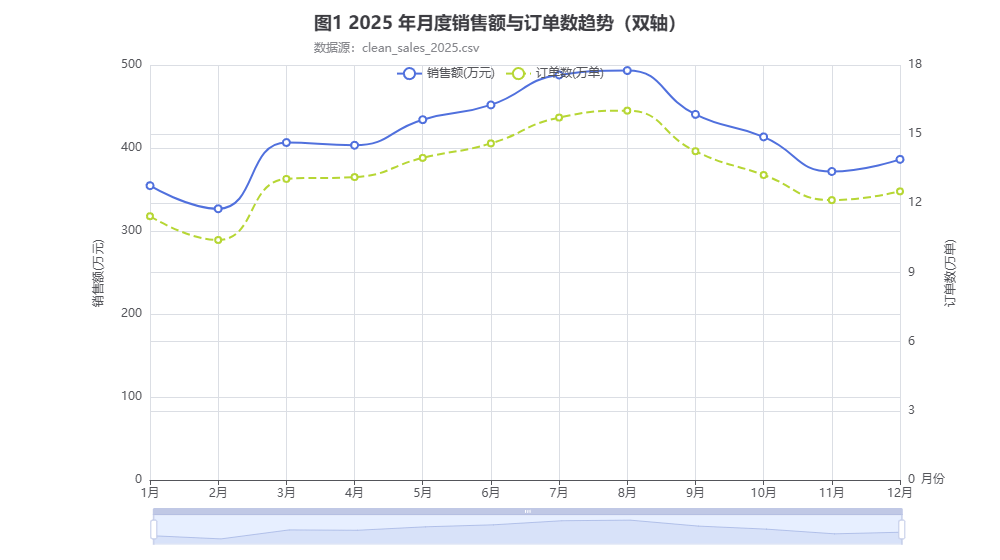

In [ ]:
labels = [f'{m}月' for m in monthly.index]
bar_line = (
    Line(init_opts=opts.InitOpts(width='1000px', height='560px', theme='light'))
    .add_xaxis(labels)
    .add_yaxis('销售额(万元)', (monthly['销售额'] / 1e4).round(1).tolist(), is_smooth=True,
               yaxis_index=0, symbol_size=7, label_opts=opts.LabelOpts(is_show=False))
    .add_yaxis('订单数(万单)', (monthly['订单数'] / 1e4).round(2).tolist(), is_smooth=True,
               yaxis_index=1, symbol_size=6, label_opts=opts.LabelOpts(is_show=False),
               linestyle_opts=opts.LineStyleOpts(type_='dashed'))
    .extend_axis(yaxis=opts.AxisOpts(name='订单数(万单)', position='right',
                                     name_location='middle', name_gap=45))
    .set_global_opts(
        title_opts=opts.TitleOpts(title='图1 2025 年月度销售额与订单数趋势（双轴）',
                                  subtitle='数据源：clean_sales_2025.csv', pos_top='10px'),
        tooltip_opts=opts.TooltipOpts(trigger='axis', axis_pointer_type='cross'),
        xaxis_opts=opts.AxisOpts(name='月份', boundary_gap=False),
        yaxis_opts=opts.AxisOpts(name='销售额(万元)', name_location='middle', name_gap=45),
        legend_opts=opts.LegendOpts(pos_top='62px'),
        datazoom_opts=[opts.DataZoomOpts(type_='slider', range_start=0, range_end=100),
                       opts.DataZoomOpts(type_='inside')],
    )
)
bar_line.render(f'{FIG}/chart1_月度销售趋势.html')
shot(f'{FIG}/chart1_月度销售趋势.html', f'{FIG}/图1_月度销售趋势.png')
show_png(f'{FIG}/图1_月度销售趋势.png')

**解读 1**：全年销售额呈明显的"单峰"走势，8 月峰值日均 6 365 元、1 月低谷日均 4 576 元，峰谷差 **39.1%**；周末日均比工作日高 **15.6%**，说明这是**夏季 + 周末双驱动**的生鲜零售结构。
销售额与订单数高度同步（r = **0.844**），客单价与销售额几乎不相关（r = −0.007）：增长来自**客流（订单数）**，客单价全年稳定在 31.8–32.3 元。
业务含义：备货、人力、排班按"夏季峰值 × 周末系数"配置；1—2 月是现金流与库存压力窗口，宜用冬季礼盒 / 火锅食材组合对冲季节性。

### 图2 门店销售地理气泡图（Matplotlib 经纬度定位）

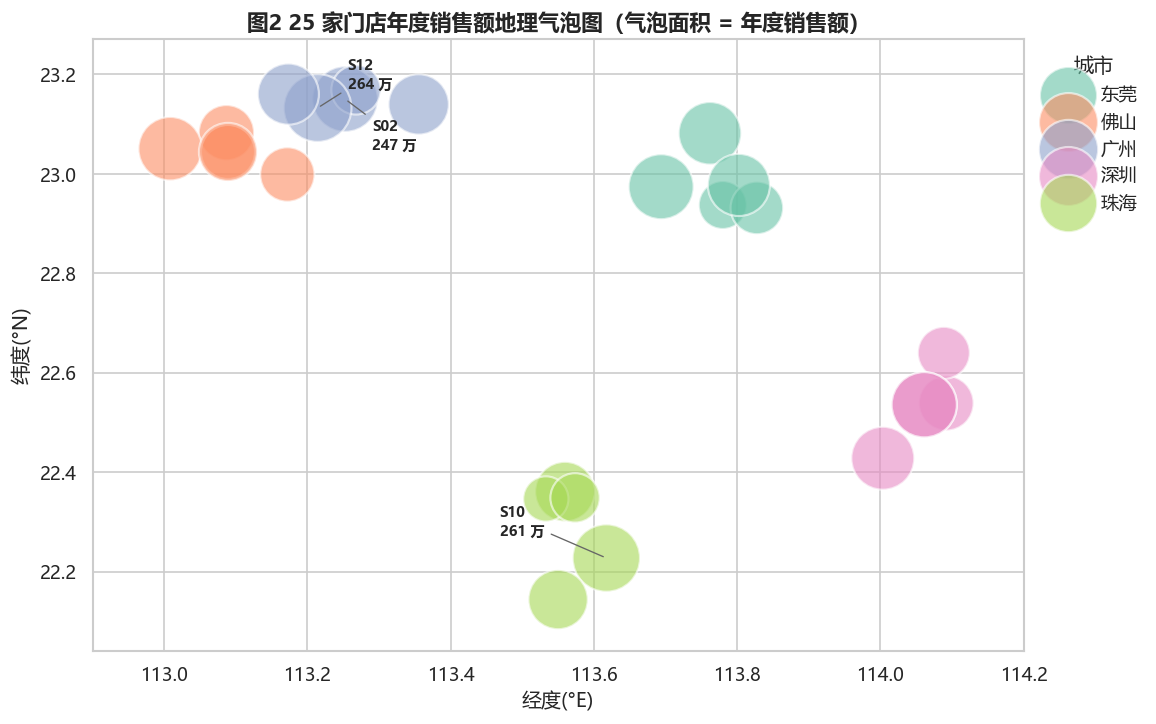

In [ ]:
coord = clean_info.set_index('门店编码')
city_colors = dict(zip(sorted(store['城市'].unique()), sns.color_palette('Set2', 5)))
fig, ax = plt.subplots(figsize=(9.8, 6.2))
for c, g in store.groupby('城市'):
    ax.scatter(g['门店编码'].map(coord['门店经度']), g['门店编码'].map(coord['门店纬度']),
               s=g['年度销售额'] / 1600, alpha=0.6, color=city_colors[c], label=c,
               edgecolor='white', linewidth=1.3)
# 标注销售 Top3 门店（箭头 + 销售额），位移错开避免重叠
for k, (_, r) in enumerate(store.nlargest(3, '年度销售额').iterrows()):
    ax.annotate(f"{r['门店编码']}\n{r['年度销售额'] / 1e4:.0f} 万",
                (coord.loc[r['门店编码'], '门店经度'], coord.loc[r['门店编码'], '门店纬度']),
                textcoords='offset points', xytext=[(18, 12), (-64, 14), (16, -30)][k],
                fontsize=8.5, fontweight='bold',
                arrowprops=dict(arrowstyle='-', lw=0.8, color='#666666'))
ax.set_xlabel('经度(°E)'); ax.set_ylabel('纬度(°N)')
ax.set_title('图2 25 家门店年度销售额地理气泡图（气泡面积 = 年度销售额）', fontsize=13, fontweight='bold')
ax.legend(title='城市', loc='upper left', bbox_to_anchor=(1.01, 1.0), frameon=False)
ax.margins(0.10)
plt.tight_layout(); plt.savefig(f'{FIG}/图2_门店地理气泡图.png', dpi=160, bbox_inches='tight')
plt.show()

**解读 2**：25 家门店全部落在珠三角（经度 113.0–114.1°、纬度 22.1–23.2°），无远距离扩张，差异只来自**城市内区位与门店体量**。
气泡最大为广州 12 店（264.4 万元）、珠海 10 店（261.0 万元），最小为珠海 15 店（117.9 万元），**头尾差 2.24 倍**；门店年度销售额变异系数 0.217，远小于季节波动（39.1%）——"体量决定水平线，季节决定波动"。
城市总量梯度为广州 1 075.7 万 > 深圳 1 046.3 万 > 东莞 981.9 万 > 佛山 940.5 万 > 珠海 926.1 万（首尾差 16.2%），客单价全部在 31.8–32.3 元；关键发现是**营业面积与年度销售额 r = 0.990**——销售规模几乎由门店面积线性决定。

### 图3 区域 × 业态 日均销售额对比（Matplotlib 分组柱状）

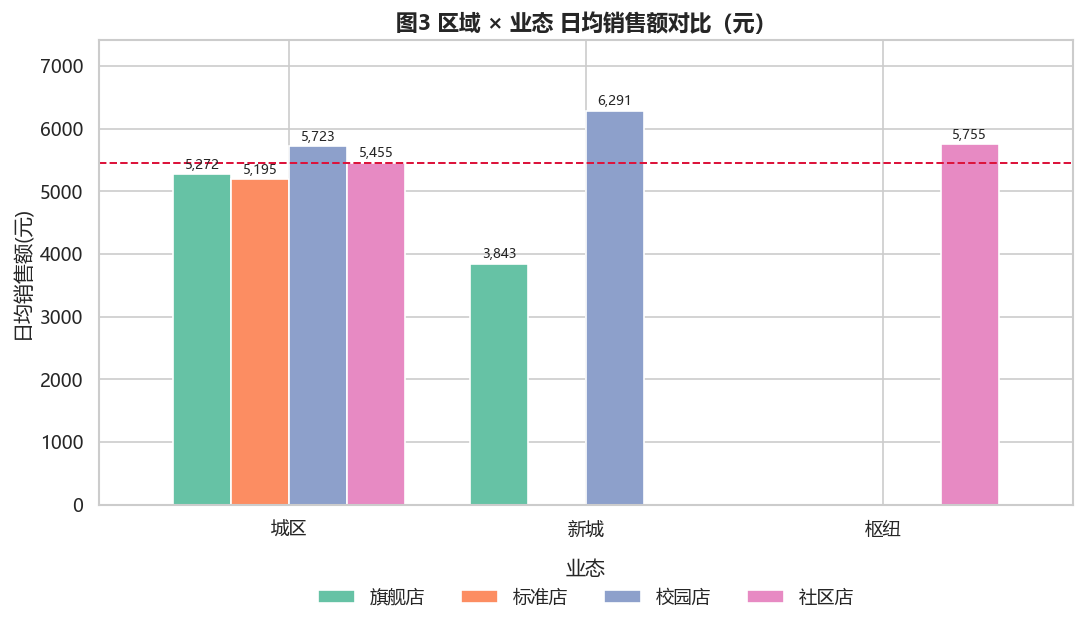

In [ ]:
pivot_area_biz = clean_sales.pivot_table(index='区域', columns='业态', values='销售额(元)', aggfunc='mean')
fig, ax = plt.subplots(figsize=(9.2, 5.4))
pivot_area_biz.plot(kind='bar', ax=ax, color=sns.color_palette('Set2', 4), edgecolor='white', width=0.78)
# 逐柱标注，缺失组合（该区域无该业态门店）不标 0
for j, biz_name in enumerate(pivot_area_biz.columns):
    for i, area_name in enumerate(pivot_area_biz.index):
        v = pivot_area_biz.loc[area_name, biz_name]
        if pd.notna(v):
            ax.text(i + (j - 1.5) * 0.195, v + 90, f'{v:,.0f}', ha='center', fontsize=8)
ax.set_title('图3 区域 × 业态 日均销售额对比（元）', fontsize=13, fontweight='bold')
ax.set_ylabel('日均销售额(元)'); ax.set_xlabel('')
ax.set_ylim(0, pivot_area_biz.max().max() * 1.18)
ax.legend(title='业态', ncol=4, loc='upper center', bbox_to_anchor=(0.5, -0.08), frameon=False)
ax.set_xticklabels(pivot_area_biz.index, rotation=0)
ax.axhline(clean_sales['销售额(元)'].mean(), color='crimson', ls='--', lw=1.2, label='全公司日均')
plt.tight_layout(); plt.savefig(f'{FIG}/图3_区域业态销售对比.png', dpi=160, bbox_inches='tight')
plt.show()

**解读 3**：区域维度几乎无差异——枢纽 5 755 元、新城 5 475 元、城区 5 412 元（20 家店），极差仅 **6.3%**；业态维度日均从旗舰店 4 795 元到校园店 5 913 元，差异 23%。
但**坪效否定了"业态效率差异"的直觉**：四业态年均坪效 12 127–12 219 元/㎡，极差不足 1%；结合面积与销售额 r = 0.990，说明日均差异几乎完全由**营业面积**解释（校园店平均 177 ㎡ > 旗舰店 144 ㎡），而非经营质量。
交叉看：新城校园店日均最高（6 291 元）、新城旗舰店最低（3 843 元）；经营含义是门店模型高度标准化，**扩店约等于扩面积**，开店评估应用"面积 × 12 200 元/㎡·年"做销售预测，改进重心放在坪效与库存周转上。

### 图4 四大品类销售构成（pyecharts 圆环饼：交互提示 + 图例筛选）

交互查看见 `图表/chart4_品类销售构成.html`。

交互图预览已截取: 图表/图4_品类销售构成.png


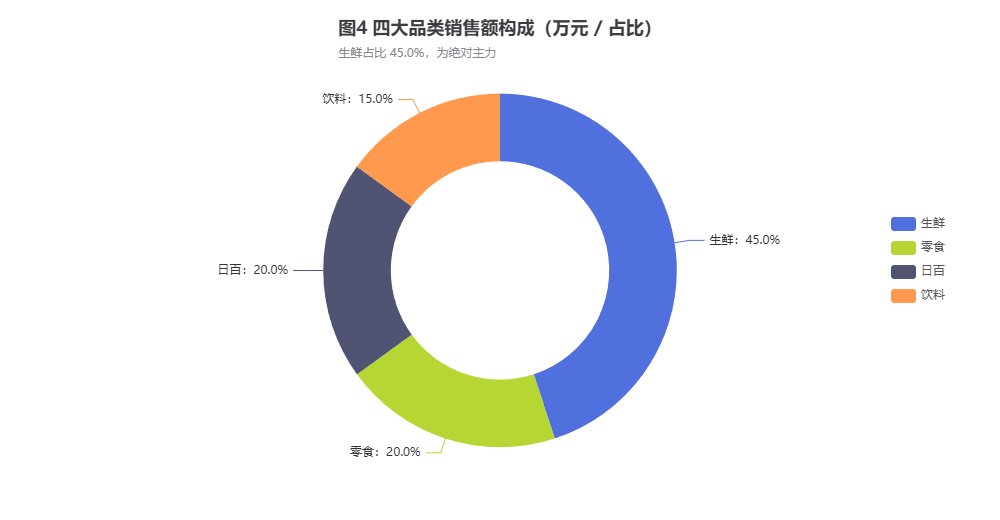

In [ ]:
pie = (
    Pie(init_opts=opts.InitOpts(width='1000px', height='520px'))
    .add('销售额', [(k.replace('销售额', ''), round(v / 1e4, 1)) for k, v in cat_total.items()],
         radius=['42%', '68%'], center=['50%', '52%'],
         label_opts=opts.LabelOpts(formatter=JsCode(
             "function(p){return p.name + '：' + p.percent.toFixed(1) + '%';}")))
    .set_global_opts(
        title_opts=opts.TitleOpts(title='图4 四大品类销售额构成（万元 / 占比）', subtitle='生鲜占比 45.0%，为绝对主力'),
        legend_opts=opts.LegendOpts(orient='vertical', pos_right='5%', pos_top='middle'),
        tooltip_opts=opts.TooltipOpts(trigger='item', formatter='{b}<br/>销售额 {c} 万元 ({d}%)'))
)
pie.render(f'{FIG}/chart4_品类销售构成.html')
shot(f'{FIG}/chart4_品类销售构成.html', f'{FIG}/图4_品类销售构成.png')
show_png(f'{FIG}/图4_品类销售构成.png')

**解读 4**：生鲜销售额 2 236.6 万元，占四品类合计 **45.0%**；零食与日百几乎持平（各 20.0%），饮料 15.0%——生鲜约为其余三类合计的 0.82 倍。
结构在区域间高度一致（生鲜 45.0%–45.1%），更关键的是**不同"主推品类"的门店组之间四品类结构完全相同**——"主推品类"目前只是营销标签，未改变销售结构。
经营含义：生鲜是流量核心但损耗最高，应把"订货—损耗—毛利"联动做日盘点；零食 / 日百作为高毛利标品承担利润，饮料围绕高温档期做冰柜前移；"主推品类"需真正落到陈列与堆头才有意义。

### 图5 区域 → 品类 销售额流向（pyecharts 桑基图：交互高亮链路）

交互查看见 `图表/chart5_区域品类流向桑基.html`：悬浮节点可高亮上下游链路，直观看到各区域销售额如何分配至四品类。

交互图预览已截取: 图表/图5_区域品类流向桑基.png


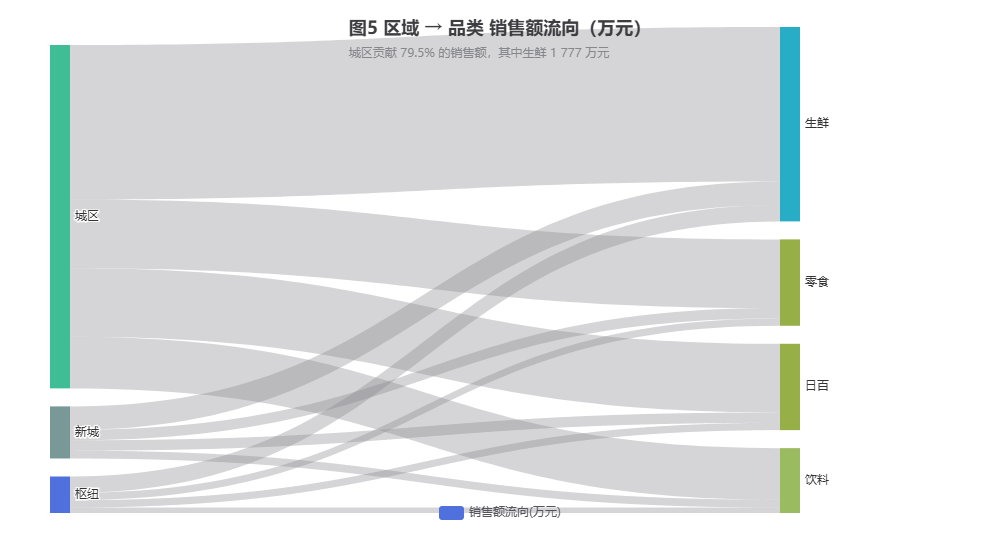

In [ ]:
areas = list(area_cat.index)
cats = [c.replace('销售额', '') for c in cat_cols]
nodes = [{'name': a} for a in areas] + [{'name': c} for c in cats]
links = [{'source': a, 'target': c, 'value': round(float(area_cat.loc[a, col]) / 1e4, 1)}
         for a in areas for col, c in zip(cat_cols, cats)]
sankey = (
    Sankey(init_opts=opts.InitOpts(width='1000px', height='540px'))
    .add('销售额流向(万元)', nodes, links,
         linestyle_opt=opts.LineStyleOpts(opacity=0.35, curve=0.5),
         label_opts=opts.LabelOpts(position='right', font_size=12),
         node_gap=18)
    .set_global_opts(
        title_opts=opts.TitleOpts(title='图5 区域 → 品类 销售额流向（万元）', subtitle='城区贡献 79.5% 的销售额，其中生鲜 1 777 万元'),
        tooltip_opts=opts.TooltipOpts(trigger='item', trigger_on='mousemove'))
)
sankey.render(f'{FIG}/chart5_区域品类流向桑基.html')
shot(f'{FIG}/chart5_区域品类流向桑基.html', f'{FIG}/图5_区域品类流向桑基.png')
show_png(f'{FIG}/图5_区域品类流向桑基.png')

**解读 5**：城区以 3 950.9 万元贡献全公司销售额的 **79.5%**，其中生鲜 1 777.2 万元；新城 599.5 万、枢纽 420.1 万，合计仅 20.5%。
三个区域的品类**结构几乎完全相同**（生鲜 45.0%–45.1%），差异全在规模——"在哪里开店决定卖多少，卖什么基本不变"。
经营含义：新城 / 枢纽（合计 5 家店）的瓶颈是门店数量与客流，不是品类结构；应优先用"社区店 + 到家 / 自提"补客流，而不是重构品类。

### 图6 日销售额分布（Seaborn 直方图 + KDE + 分组箱线）

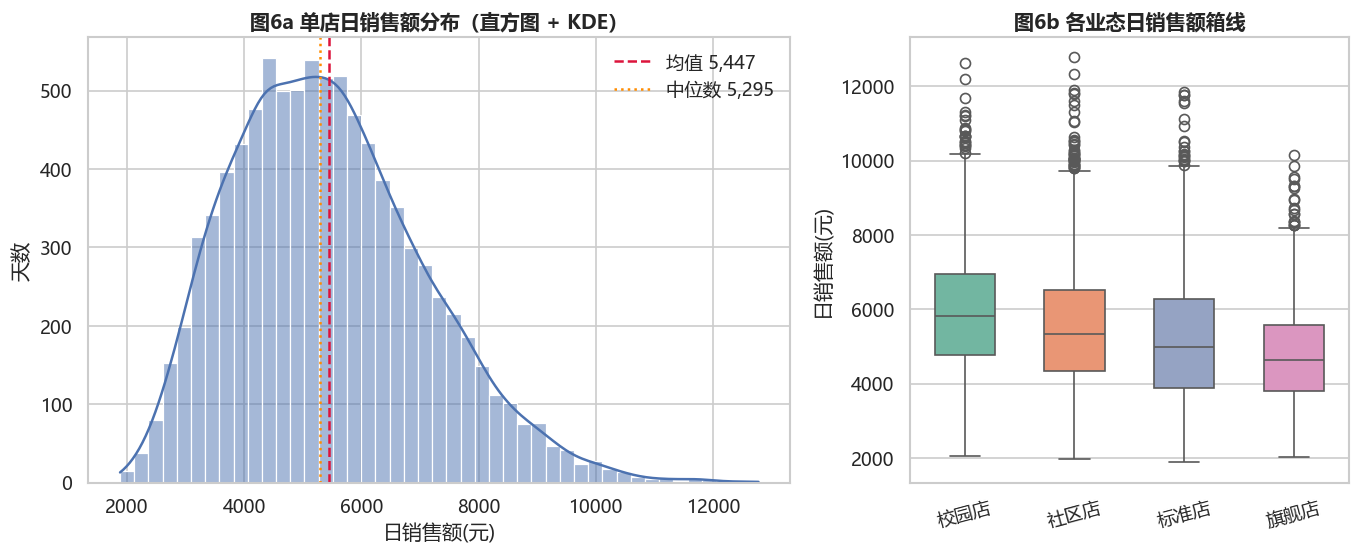

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.8), gridspec_kw={'width_ratios': [1.6, 1]})
sns.histplot(clean_sales['销售额(元)'], bins=45, kde=True, ax=axes[0], color='#4C72B0', edgecolor='white')
axes[0].axvline(clean_sales['销售额(元)'].mean(), color='crimson', ls='--', label=f'均值 {clean_sales["销售额(元)"].mean():,.0f}')
axes[0].axvline(clean_sales['销售额(元)'].median(), color='darkorange', ls=':', label=f'中位数 {clean_sales["销售额(元)"].median():,.0f}')
axes[0].set_title('图6a 单店日销售额分布（直方图 + KDE）', fontsize=12, fontweight='bold')
axes[0].set_xlabel('日销售额(元)'); axes[0].set_ylabel('天数')
axes[0].legend(frameon=False)
sns.boxplot(data=clean_sales, x='业态', y='销售额(元)', ax=axes[1], palette='Set2', width=0.55, order=['校园店', '社区店', '标准店', '旗舰店'])
axes[1].set_title('图6b 各业态日销售额箱线', fontsize=12, fontweight='bold')
axes[1].set_xlabel(''); axes[1].set_ylabel('日销售额(元)')
axes[1].tick_params(axis='x', rotation=15)
plt.tight_layout(); plt.savefig(f'{FIG}/图6_销售额分布.png', dpi=160, bbox_inches='tight')
plt.show()

**解读 6**：日销售额呈**单峰右偏**分布，均值 5 447 元 > 中位数 5 295 元，50% 的"店日"落在 4 224–6 483 元，上限 12 778 元（旺季 + 促销叠加日）。
箱线图：校园店整体最高、旗舰店最低（仅 3 家店，面积 114–172 ㎡），但各业态四分位框宽度相近——离群点不是个别异常，而是**促销日与旺季的系统性抬升**。
经营含义：用均值下目标会被旺季拉高，建议用"中位数 × 季节系数 + 促销日加成"做日目标；对单店异常日（>10 000 元）回溯其促销组合与陈列，复制可复用做法。

### 图7 气温—销售额 回归散点（Seaborn）

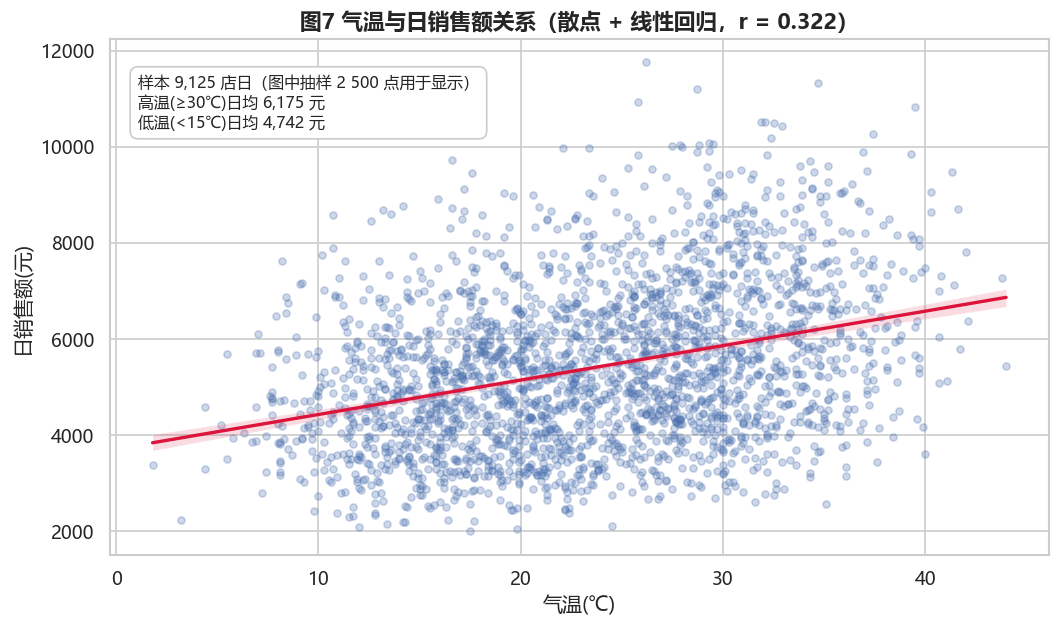

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5.4))
sns.regplot(data=clean_sales.sample(2500, random_state=42), x='气温(℃)', y='销售额(元)', ax=ax,
            scatter_kws={'alpha': 0.28, 's': 18, 'color': '#4C72B0'},
            line_kws={'color': 'crimson', 'lw': 2})
r = clean_sales['气温(℃)'].corr(clean_sales['销售额(元)'])
ax.set_title(f'图7 气温与日销售额关系（散点 + 线性回归，r = {r:.3f}）', fontsize=13, fontweight='bold')
ax.set_xlabel('气温(℃)'); ax.set_ylabel('日销售额(元)')
ax.text(0.03, 0.93, f'样本 {len(clean_sales):,} 店日（图中抽样 2 500 点用于显示）\n高温(≥30℃)日均 {clean_sales.loc[clean_sales["气温(℃)"] >= 30, "销售额(元)"].mean():,.0f} 元\n低温(<15℃)日均 {clean_sales.loc[clean_sales["气温(℃)"] < 15, "销售额(元)"].mean():,.0f} 元',
        transform=ax.transAxes, fontsize=9.5, va='top',
        bbox=dict(boxstyle='round,pad=0.5', fc='white', ec='#cccccc'))
plt.tight_layout(); plt.savefig(f'{FIG}/图7_气温销售额回归.png', dpi=160, bbox_inches='tight')
plt.show()

**解读 7**：气温与日销售额呈**中等正相关**（r = **0.322**），回归斜率约 **+69 元/℃**：气温每升高 1 ℃，单店日销售平均增加约 69 元。
高温日（≥30 ℃）日均 6 175 元，低温日（<15 ℃）日均 4 742 元，差距 **30.2%**；雨天日均比晴天低 13.0%、阴天低 7.4%，与"夏季冷饮 + 水果"的品类结构一致。
但 r 仅 0.32（促销相对提升 25.5%、雨日 −13%），气温是**调节系数而非主变量**：适合做短期备货与冰柜陈列的动态系数，预测主变量仍是面积、季节与促销日历。

### 图8 门店 × 月份 日销售额热力图（Seaborn）

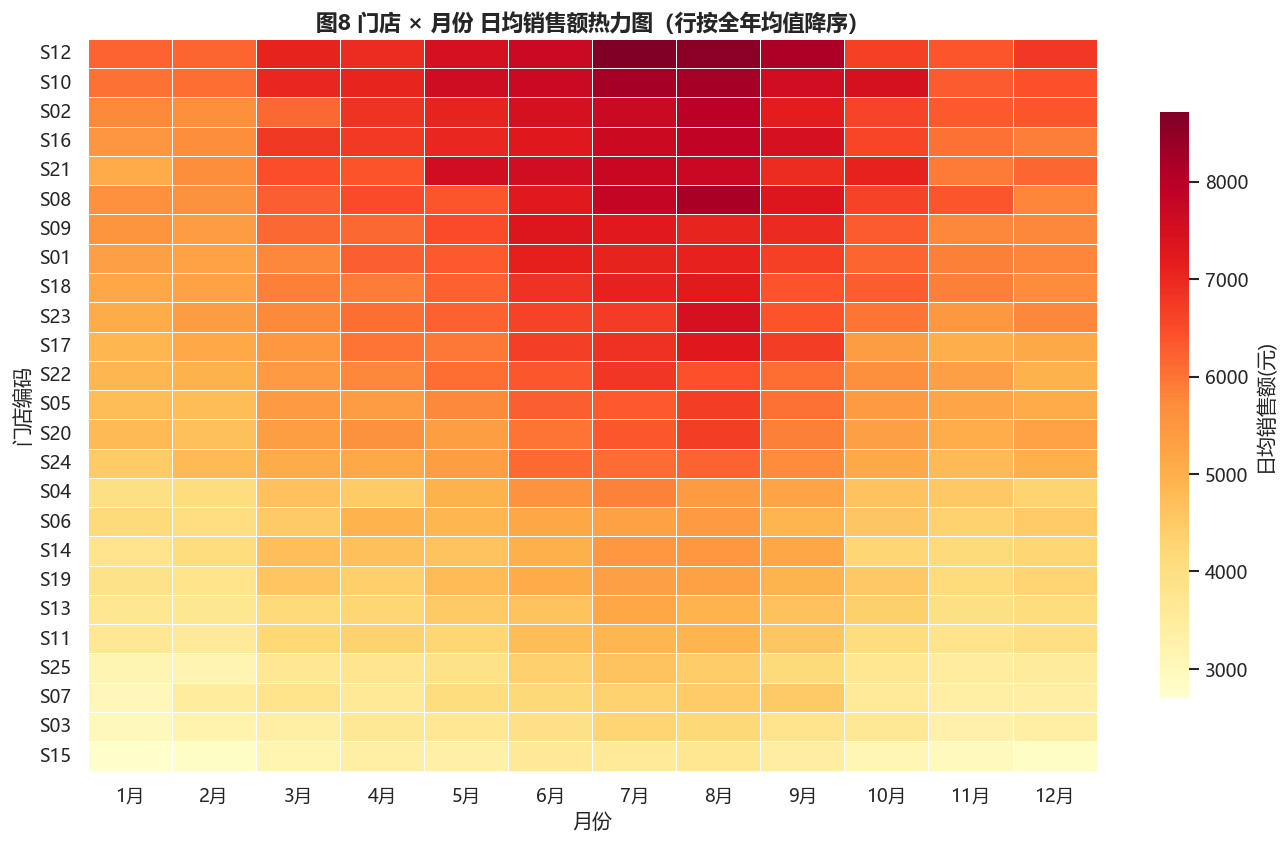

In [ ]:
hm = clean_sales.pivot_table(index='门店编码', columns='月份', values='销售额(元)', aggfunc='mean')
hm = hm.loc[hm.mean(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(11.5, 7.2))
sns.heatmap(hm, cmap='YlOrRd', ax=ax, linewidths=0.4, linecolor='white',
            cbar_kws={'label': '日均销售额(元)', 'shrink': 0.8})
ax.set_title('图8 门店 × 月份 日均销售额热力图（行按全年均值降序）', fontsize=13, fontweight='bold')
ax.set_xlabel('月份'); ax.set_ylabel('门店编码')
ax.set_xticklabels([f'{m}月' for m in hm.columns], rotation=0)
plt.tight_layout(); plt.savefig(f'{FIG}/图8_门店月份热力图.png', dpi=160, bbox_inches='tight')
plt.show()

**解读 8**：列方向（月份）的色差贯穿所有门店、行方向（门店）深浅常年稳定，说明**季节性对所有门店同步作用**，门店排名全年几乎不变。
深色行集中在 S12（213 ㎡）、S10（217 ㎡）、S02（208 ㎡）等面积最大的门店，浅色行多为 100 余平方米的小店，再次印证"面积 → 销售"的线性关系（r = 0.990）。
经营含义：营销节奏可**全公司统一**（7—8 月加码、1—2 月促销拉新）；资源按"面积 × 坪效目标"分配，对坪效低于 12 000 元/㎡·年的门店做陈列与品类改造试点。

### 图9 城市会员画像雷达（pyecharts 交互雷达：图例筛选城市）

五个维度：会员订单渗透率、会员客单价、金卡及以上占比、微信支付占比、会员日订单占比，均已归一化到 0–100 以便同图比较。交互查看见 `图表/chart9_城市会员雷达.html`。

雷达指标原始值:
    会员订单渗透率      会员客单价  金卡及以上占比  微信支付占比  会员日订单占比
城市                                              
东莞    0.455  11002.050    0.194   0.432    0.186
佛山    0.453  10635.858    0.193   0.456    0.202
广州    0.451  11010.744    0.193   0.376    0.232
深圳    0.453  10774.488    0.179   0.451    0.204
珠海    0.455  11061.086    0.222   0.416    0.216

归一化(0-100):
    会员订单渗透率  会员客单价  金卡及以上占比  微信支付占比  会员日订单占比
城市                                          
东莞    100.0   99.5     87.4    94.7     80.2
佛山     99.6   96.2     86.9   100.0     87.1
广州     99.1   99.5     86.9    82.5    100.0
深圳     99.6   97.4     80.6    98.9     87.9
珠海    100.0  100.0    100.0    91.2     93.1


交互图预览已截取: 图表/图9_城市会员雷达.png


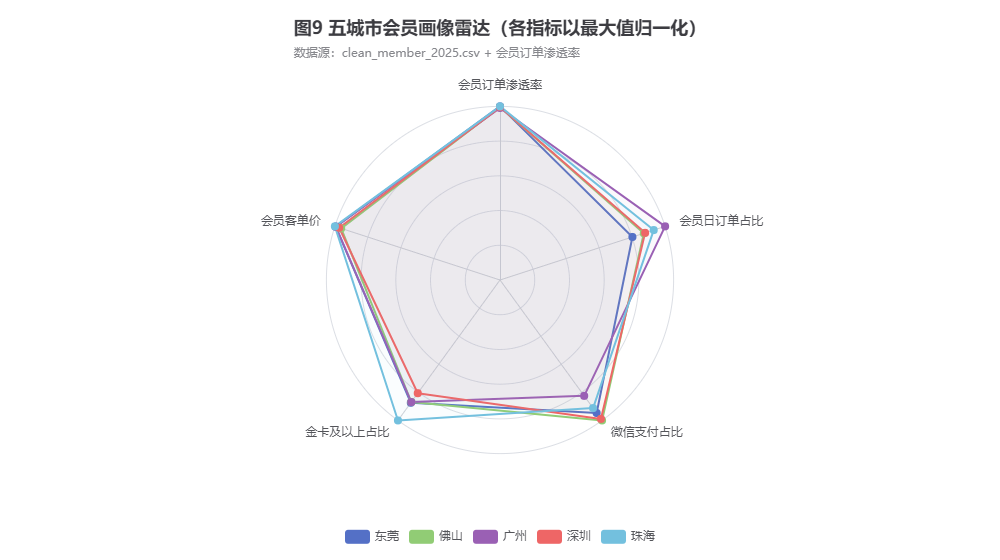

In [ ]:
radar_dim = pd.DataFrame({
    '会员订单渗透率': clean_sales.groupby('城市')['会员订单占比'].mean(),
    '会员客单价': clean_member.groupby('城市')['会员客单价'].mean(),
    '金卡及以上占比': clean_member.groupby('城市').apply(lambda d: d['等级占比_金卡'].mean() + d['等级占比_白金'].mean()),
    '微信支付占比': clean_member.groupby('城市')['支付占比_微信'].mean(),
    '会员日订单占比': clean_member.groupby('城市')['会员日订单占比'].mean(),
}).round(3)
radar_norm = (radar_dim / radar_dim.max() * 100).round(1)
print('雷达指标原始值:'); print(radar_dim.to_string())
print('\n归一化(0-100):'); print(radar_norm.to_string())

radar = Radar(init_opts=opts.InitOpts(width='1000px', height='560px'))
PALETTE = ['#5470C6', '#91CC75', '#9A60B4', '#EE6666', '#73C0DE']
radar.add_schema(schema=[opts.RadarIndicatorItem(name=k, max_=100) for k in radar_norm.columns],
                 shape='circle', radius='62%', splitline_opt=opts.SplitLineOpts(is_show=True))
for c, col in zip(radar_norm.index, PALETTE):
    radar.add(c, [[radar_norm.loc[c, k] for k in radar_norm.columns]], color=col,
              areastyle_opts=opts.AreaStyleOpts(opacity=0.04), label_opts=opts.LabelOpts(is_show=False))
radar.set_series_opts()
radar.set_global_opts(
    title_opts=opts.TitleOpts(title='图9 五城市会员画像雷达（各指标以最大值归一化）',
                              subtitle='数据源：clean_member_2025.csv + 会员订单渗透率'),
    legend_opts=opts.LegendOpts(pos_bottom='2%', orient='horizontal'),
    tooltip_opts=opts.TooltipOpts(trigger='item'))
radar.render(f'{FIG}/chart9_城市会员雷达.html')
shot(f'{FIG}/chart9_城市会员雷达.html', f'{FIG}/图9_城市会员雷达.png')
show_png(f'{FIG}/图9_城市会员雷达.png')

**解读 9**：五城雷达轮廓几乎重合——会员订单渗透率 45.1%–45.5%、会员客单价 10 636–11 061 元，说明会员体系是**统一模板**，不存在"某城会员质量差"的问题。
相对差异：珠海金卡及以上占比 22.2% 最高（广州 19.3%、佛山 19.5%、深圳 17.9% 最低）；佛山微信支付占比 45.6% 最高、广州 37.6% 最低；广州会员日订单占比 23.2% 最高、东莞 18.6% 最低。
经营含义：会员增长应转向**等级结构升级**——金卡 + 白金仅占 19.5% 订单，客单价却达 13 925 / 13 661 元，是普通会员（8 406 元）的 1.66 倍；支付侧对微信 + 支付宝（78.5%）做小程序券到店核销。

### 图10 城市 × 月份 3D 销售柱状（Matplotlib 3D）

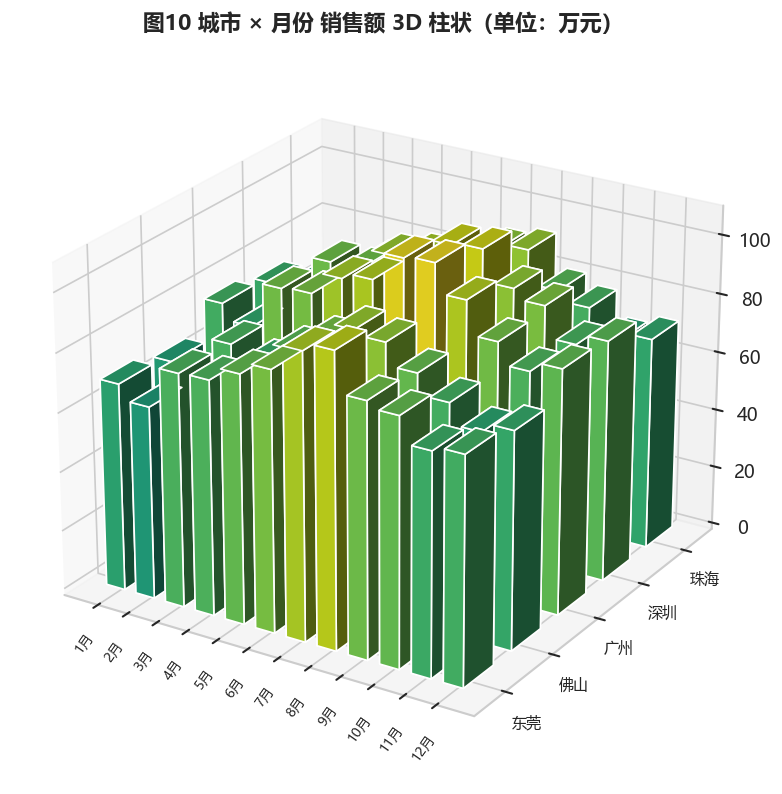

In [ ]:
city_month = clean_sales.pivot_table(index='城市', columns='月份', values='销售额(元)', aggfunc='sum') / 1e4
fig = plt.figure(figsize=(11.5, 7.2))
ax = fig.add_subplot(111, projection='3d')
fig.subplots_adjust(left=0.02, right=0.90, bottom=0.04, top=0.90)
_x = np.arange(len(city_month.columns)); _y = np.arange(len(city_month.index))
_xx, _yy = np.meshgrid(_x, _y)
x, y = _xx.ravel(), _yy.ravel()
top = city_month.values.ravel()
ax.bar3d(x, y, np.zeros_like(top), 0.62, 0.62, top, shade=True,
         color=plt.cm.viridis(top / top.max()))
ax.set_xticks(_x + 0.3)
ax.set_xticklabels([f'{m}月' for m in city_month.columns], rotation=55, fontsize=8)
ax.set_yticks(_y + 0.3); ax.set_yticklabels(city_month.index, fontsize=9)
ax.set_zlabel('')
ax.set_title('图10 城市 × 月份 销售额 3D 柱状（单位：万元）', fontsize=13, fontweight='bold')
ax.view_init(elev=24, azim=-58)
plt.tight_layout(); plt.savefig(f'{FIG}/图10_城市月份3D柱状.png', dpi=160, bbox_inches='tight')
plt.show()

**解读 10**：3D 视图把"城市 × 月份"的双重差异一次呈现：高度差（月份）明显大于纵深差（城市），所有城市都是 7—8 月最高、1—2 月最低。
广州几乎每个月都是最高（8 月峰值 107.5 万元），珠海 / 佛山同月与广州相差约 13%–14%，五城月度曲线形状几乎平行。
经营含义：总部可对全部城市使用**同一套季节系数**（8 月较年均 +17%、1 月 −16%）做预算与备货；城市间差距靠"门店体量与选址"消化，而非差异化策略。

## 5. 结论、建议与关键指标导出

In [ ]:
summary = {
    '数据规模': {'清洗后事实表行数': int(len(clean_sales)), '删除重复行': int(n_dup),
              '会员聚合门店数': int(len(clean_member)), '会员订单数': int(len(clean_member_orders))},
    '时间': {'全年销售额': round(float(clean_sales['销售额(元)'].sum()), 2),
           '日均销售额': round(float(clean_sales['销售额(元)'].mean()), 2),
           '峰值月': int(monthly['日均销售额'].idxmax()), '峰值月日均': round(float(monthly['日均销售额'].max()), 2),
           '低谷月': int(monthly['日均销售额'].idxmin()), '低谷月日均': round(float(monthly['日均销售额'].min()), 2),
           '峰谷差%': round(float(monthly['日均销售额'].max() / monthly['日均销售额'].min() - 1) * 100, 1),
           '周末溢价%': round(float(wk[1] / wk[0] - 1) * 100, 1)},
    '城市': {k: round(float(v), 2) for k, v in city['销售额'].items()},
    '城市占比%': {k: float(v) for k, v in city['销售额占比%'].items()},
    '业态日均': {k: round(float(v), 2) for k, v in biz['日均销售额'].items()},
    '品类': {k: round(float(v), 2) for k, v in cat_total.items()},
    '品类占比%': {k.replace('销售额', ''): float(v) for k, v in cat_tbl['占比%'].items()},
    '会员': {'渗透率': round(float(member_ratio), 4),
           '会员销售额估算': round(float(clean_sales['会员销售额估算'].sum()), 2),
           '等级订单占比%': {k: round(float(v), 2) for k, v in level['订单占比%'].items()},
           '支付订单占比%': {k: round(float(v), 2) for k, v in pay['订单占比%'].items()},
           '会员日客单价提升%': round(float(mem_day.loc[1, 'mean'] / mem_day.loc[0, 'mean'] - 1) * 100, 1)},
    '促销天气': {'促销日占比%': round(float(clean_sales['是否促销'].mean() * 100), 1),
             '促销销售贡献%': round(float(sale[clean_sales['是否促销'] == 1].sum() / sale.sum() * 100), 1),
             '促销提升%': {k: float(v) for k, v in promo['相对无促销%'].items()},
             '气温相关': round(float(temp.corr(sale)), 3),
             '高温日均': round(float(sale[temp >= 30].mean()), 2),
             '低温日均': round(float(sale[temp < 15].mean()), 2),
             '雨天相对晴天%': round(float(weather.loc['雨', '相对晴天%']), 1)},
    '相关性': {k: round(float(v), 3) for k, v in corr['销售额(元)'].drop('销售额(元)').items()},
}
with open(f'{FIG}/analysis_summary.json', 'w', encoding='utf-8') as f:
    json.dump(summary, f, ensure_ascii=False, indent=2)

print('一、核心结论')
print(f'1) 全年销售 {summary["时间"]["全年销售额"] / 1e4:,.1f} 万元，日均 {summary["时间"]["日均销售额"]:,.0f} 元；'
      f'{summary["时间"]["峰值月"]} 月峰值日均 {summary["时间"]["峰值月日均"]:,.0f} 元，{summary["时间"]["低谷月"]} 月低谷 '
      f'{summary["时间"]["低谷月日均"]:,.0f} 元，峰谷差 {summary["时间"]["峰谷差%"]}%，周末溢价 {summary["时间"]["周末溢价%"]}%。')
print(f'2) 城市规模 广州 {summary["城市"]["广州"] / 1e4:,.1f} 万 > 深圳 {summary["城市"]["深圳"] / 1e4:,.1f} 万 > 东莞 '
      f'{summary["城市"]["东莞"] / 1e4:,.1f} 万 > 佛山 {summary["城市"]["佛山"] / 1e4:,.1f} 万 > 珠海 {summary["城市"]["珠海"] / 1e4:,.1f} 万；'
      f'业态中校园店日均最高 {summary["业态日均"]["校园店"]:,.0f} 元，旗舰店最低 {summary["业态日均"]["旗舰店"]:,.0f} 元。')
print(f'3) 品类：生鲜 {summary["品类占比%"]["生鲜"]}% > 零食 {summary["品类占比%"]["零食"]}% ≈ 日百 {summary["品类占比%"]["日百"]}% > 饮料 {summary["品类占比%"]["饮料"]}%。')
print(f'4) 会员：订单渗透率 {summary["会员"]["渗透率"]:.1%}，会员贡献销售约 {summary["会员"]["会员销售额估算"] / 1e4:,.1f} 万元；'
      f'支付以微信 {summary["会员"]["支付订单占比%"]["微信"]}% + 支付宝 {summary["会员"]["支付订单占比%"]["支付宝"]}% 为主，合计 {summary["会员"]["支付订单占比%"]["微信"] + summary["会员"]["支付订单占比%"]["支付宝"]:.1f}%。')
print(f'5) 促销：促销日占比 {summary["促销天气"]["促销日占比%"]}% 却贡献 {summary["促销天气"]["促销销售贡献%"]}% 销售额，日均提升 '
      f'{summary["促销天气"]["促销提升%"]["折扣"]}%（折扣）/{summary["促销天气"]["促销提升%"]["满减"]}%（满减）/'
      f'{summary["促销天气"]["促销提升%"]["会员日"]}%（会员日）；气温 r = {summary["促销天气"]["气温相关"]}，'
      f'高温日均 {summary["促销天气"]["高温日均"]:,.0f} 元 vs 低温 {summary["促销天气"]["低温日均"]:,.0f} 元。')
print('\n二、行动建议')
print('· 备货与人力：以 8 月峰值为基准（日均为年均 117%），周末再乘 1.16 系数；1—2 月压缩库存周转天数，推冬季礼盒/火锅食材组合对冲淡季。')
print('· 门店模型：销售规模≈营业面积 × 12 200 元/㎡·年（r = 0.990），开店评估直接用该公式做预测与审批；四业态坪效极差不足 1%，竞争重点放在坪效提升（陈列、品类组合、周转）而非业态切换。')
print('· 品类策略：生鲜做流量与心智（45%），用零食/日百高毛利标品对冲生鲜损耗，饮料围绕高温档期做冰柜前移陈列。')
print('· 会员运营：金卡+白金客单价是普通会员的 1.66 倍但仅占 19.5% 订单，应做等级升级任务与专属权益；微信+支付宝占 78.5%，打通小程序券到店核销；会员日客单价仅高 0.4%，其价值在"提频次"而非"提客单"。')
print('· 促销节奏：折扣/满减/会员日三类效果接近（+25% 左右），建议"周中满减 + 周末会员日"错峰，避免全周打折稀释毛利。')

一、核心结论
1) 全年销售 4,970.5 万元，日均 5,447 元；8 月峰值日均 6,365 元，1 月低谷 4,576 元，峰谷差 39.1%，周末溢价 15.6%。
2) 城市规模 广州 1,075.7 万 > 深圳 1,046.3 万 > 东莞 981.9 万 > 佛山 940.5 万 > 珠海 926.1 万；业态中校园店日均最高 5,913 元，旗舰店最低 4,795 元。
3) 品类：生鲜 45.0% > 零食 20.0% ≈ 日百 20.0% > 饮料 15.0%。
4) 会员：订单渗透率 45.3%，会员贡献销售约 2,255.6 万元；支付以微信 42.5% + 支付宝 36.0% 为主，合计 78.5%。
5) 促销：促销日占比 29.6% 却贡献 34.5% 销售额，日均提升 25.8%（折扣）/25.1%（满减）/25.8%（会员日）；气温 r = 0.322，高温日均 6,175 元 vs 低温 4,742 元。

二、行动建议
· 备货与人力：以 8 月峰值为基准（日均为年均 117%），周末再乘 1.16 系数；1—2 月压缩库存周转天数，推冬季礼盒/火锅食材组合对冲淡季。
· 门店模型：销售规模≈营业面积 × 12 200 元/㎡·年（r = 0.990），开店评估直接用该公式做预测与审批；四业态坪效极差不足 1%，竞争重点放在坪效提升（陈列、品类组合、周转）而非业态切换。
· 品类策略：生鲜做流量与心智（45%），用零食/日百高毛利标品对冲生鲜损耗，饮料围绕高温档期做冰柜前移陈列。
· 会员运营：金卡+白金客单价是普通会员的 1.66 倍但仅占 19.5% 订单，应做等级升级任务与专属权益；微信+支付宝占 78.5%，打通小程序券到店核销；会员日客单价仅高 0.4%，其价值在"提频次"而非"提客单"。
· 促销节奏：折扣/满减/会员日三类效果接近（+25% 左右），建议"周中满减 + 周末会员日"错峰，避免全周打折稀释毛利。
